# Training experiments: first model exploration (CNN)

**EGN 6216 · AI Systems · Module 7 homework** · Mashoukur Rahaman  
**Project:** AI-based land subsidence susceptibility mapping, Tulare-Corcoran study area (San Joaquin Valley)

This is the CNN version of the homework notebook. It follows the six steps of the assignment, with a small convolutional network on neighbourhood patches of the 500 m grid as the selected candidate and the Random Forest runs from `training_experiments.ipynb` as reference points on exactly the same folds and metric. Step 7 (new in this version) explains the CNN with LIME and checks the explanations.

**Sections:** Step 1 role of AI and candidates · Setup · Step 2 data (including putting the table back on the grid) · Step 3 first run · Step 4 evaluation · Step 5 errors and practical constraints · Step 6 one targeted change · leakage and sanity checks · **Step 7 explanations with LIME** · experiment results and notes.

**Evaluation rule.** The 967 labeled test cells (14 held-out 5 km blocks from `insar_label.ipynb`) are not scored and their labels are not used anywhere in this notebook; their predictor values appear only in places that do not score anything (the groundwater value count, the raster, the patches around neighbouring cells, and the timing of a whole-grid prediction). All scores below are validation scores from cross-validation over whole blocks of the 40 training blocks.

**To rerun:** open the notebook from the repository root so that `data/subsidence_dataset_processed.csv` (written by `insar_label.ipynb`) is found. It needs TensorFlow (`pip install tensorflow`, CPU is enough) in addition to the packages in `requirements.txt`, and takes several minutes because of the repeated runs. Step 7 also needs the `lime` package (`pip install lime==0.2.0.1`, which installs scikit-image as well) and adds a few minutes.

## Setup

In [1]:
"""Prints the versions the notebooks depend on and runs a tiny TensorFlow test.

Run:  python check_env.py
"""
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"   # must be set before tensorflow is first imported (the setup cell below sets it too, but only in time if this cell does not run first)
import platform
import sys
from importlib import metadata

print(f"Python      {platform.python_version()}  ({sys.executable})")
print(f"Platform    {platform.platform()}")

for pkg in ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "pyproj",
            "tensorflow", "keras", "ipykernel", "jupyterlab"]:
    try:
        print(f"{pkg:<12}{metadata.version(pkg)}")
    except metadata.PackageNotFoundError:
        print(f"{pkg:<12}NOT INSTALLED")

try:
    import os
    os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
    import numpy as np
    import tensorflow as tf
    x = np.random.default_rng(0).normal(size=(64, 5, 5, 3)).astype("float32")
    y = np.random.default_rng(1).integers(0, 4, size=64)
    model = tf.keras.Sequential([
        tf.keras.layers.Input((5, 5, 3)),
        tf.keras.layers.Conv2D(4, 3, activation="relu"),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(4, activation="softmax"),
    ])
    model.compile("adam", "sparse_categorical_crossentropy")
    model.fit(x, y, epochs=1, verbose=0)
    print("TensorFlow  small CNN trained: OK")
except Exception as exc:
    print(f"TensorFlow  FAILED: {exc!r}")

Python      3.12.15  (C:\Users\m.rahaman\.conda\envs\subsidence-ml\python.exe)
Platform    Windows-11-10.0.26100-SP0
numpy       2.5.4
pandas      3.1.0
scipy       1.18.1
scikit-learn1.9.1
matplotlib  3.11.2
pyproj      3.8.0
tensorflow  2.21.0
keras       3.15.1
ipykernel   7.4.0
jupyterlab  4.6.4
TensorFlow  small CNN trained: OK


In [2]:
import os, sys, time, json, hashlib, platform, tempfile, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"               # hide TensorFlow's C++ log messages
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"               # no oneDNN fast paths, so floating-point results do not depend on the CPU
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf                                  # Keras 3 runs on top of TensorFlow here (pip install tensorflow)
import keras
from keras import layers
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, precision_recall_fscore_support

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
try:
    tf.config.experimental.enable_op_determinism()      # same seed -> same result on the same machine and versions
except Exception as e:
    print("could not enable deterministic ops:", e)

SEED = 42                      # one seed for the CV folds, the weight initialisation and the Random Forest reference
CLASSES = ["very_low", "low", "moderate", "high", "very_high"]
CLASS_ID = {c: i for i, c in enumerate(CLASSES)}

print("python", sys.version.split()[0], "| scikit-learn", sklearn.__version__, "| tensorflow", tf.__version__, "| keras", keras.__version__,
      "| pandas", pd.__version__, "| numpy", np.__version__)
print("machine:", platform.platform(), "| logical CPUs:", os.cpu_count(), "| GPUs visible to TensorFlow:", len(tf.config.list_physical_devices("GPU")))

python 3.12.15 | scikit-learn 1.9.1 | tensorflow 2.21.0 | keras 3.15.1 | pandas 3.1.0 | numpy 2.5.4
machine: Windows-11-10.0.26100-SP0 | logical CPUs: 32 | GPUs visible to TensorFlow: 0


## Step 2: Load and inspect the data

I load the processed table from Milestone 3, check its checksum against `label_build_log.json`, and keep only the labeled cells of the training blocks as development data. Everything that learns from data (imputer, encoder, forest) is fitted inside each cross-validation fold on that fold's training cells only.

In [3]:
DATA = next(p for p in ["data/subsidence_dataset_processed.csv", "../data/subsidence_dataset_processed.csv"] if os.path.exists(p))
EXPECTED_SHA256 = "ad033f34e110042e193ef9135dcae13e5905e9a487d2b881265aa53dc35cbd50"   # output_csv.sha256 in data/label_build_log.json

with open(DATA, "rb") as f:
    sha = hashlib.sha256(f.read()).hexdigest()
print("file:", DATA)
print("sha256:", sha)
print("matches the checksum in label_build_log.json:", sha == EXPECTED_SHA256)

df_all = pd.read_csv(DATA)                       # all 5,192 cells (predictors only are used below, except the training labels)
labeled = df_all["susceptibility_class"].notna()
print("\ncells:", len(df_all), "| columns:", df_all.shape[1])
print("labeled:", int(labeled.sum()), "| no label (no usable InSAR point):", int((~labeled).sum()))
print("labeled cells by split:", df_all.loc[labeled, "split"].value_counts().to_dict())

# Development data = labeled cells of the 40 training blocks. The 967 labeled test cells are set aside here
# and never touched again in this notebook.
dev = df_all[labeled & (df_all["split"] == "train")].reset_index(drop=True)
N_TEST_UNUSED = int((labeled & (df_all["split"] == "test")).sum())
print("\ndevelopment cells:", len(dev), "in", dev["block_id"].nunique(), "blocks | test cells left unused:", N_TEST_UNUSED)

y = dev["susceptibility_class"].map(CLASS_ID).to_numpy()
groups = dev["block_id"].to_numpy()

file: data/subsidence_dataset_processed.csv
sha256: ad033f34e110042e193ef9135dcae13e5905e9a487d2b881265aa53dc35cbd50
matches the checksum in label_build_log.json: True

cells: 5192 | columns: 37
labeled: 3539 | no label (no usable InSAR point): 1653
labeled cells by split: {'train': 2572, 'test': 967}

development cells: 2572 in 40 blocks | test cells left unused: 967


In [4]:
# class balance of the development cells (cut points were computed from these cells, so they are balanced by construction)
bal = dev["susceptibility_class"].value_counts().reindex(CLASSES)
print("class counts (development cells):")
print(pd.DataFrame({"cells": bal, "share_%": (100 * bal / len(dev)).round(1)}).T.to_string())

print("\ncells per block: min", dev.groupby("block_id").size().min(), "| median", int(dev.groupby("block_id").size().median()),
      "| max", dev.groupby("block_id").size().max())

# missing values among the development cells
miss = dev.isna().sum()
miss = miss[miss > 0].drop(["insar_disp_window", "subsidence"], errors="ignore")
print("\nmissing values among development cells (columns with any):")
print(pd.DataFrame({"missing": miss, "share_%": (100 * miss / len(dev)).round(1)}).to_string())
print("\nlabel support: insar_n_points median", int(dev["insar_n_points"].median()),
      "| cells resting on 1 point:", int((dev["insar_n_points"] == 1).sum()),
      "| on fewer than 3:", int((dev["insar_n_points"] < 3).sum()))

class counts (development cells):
susceptibility_class  very_low    low  moderate   high  very_high
cells                    515.0  514.0     514.0  514.0      515.0
share_%                   20.0   20.0      20.0   20.0       20.0

cells per block: min 10 | median 66 | max 95

missing values among development cells (columns with any):
                          missing  share_%
mukey                         113      4.4
drainagecl                    202      7.9
hydgrp                        125      4.9
taxclname                     202      7.9
clay_pct                      202      7.9
sand_pct                      202      7.9
silt_pct                      202      7.9
organic_matter_pct            202      7.9
ksat_um_per_s                 202      7.9
available_water_capacity      202      7.9

label support: insar_n_points median 6 | cells resting on 1 point: 343 | on fewer than 3: 620


**What I filled, dropped or left unchanged.**
- **Soil gaps (filled, inside each fold).** 202 of the 2,572 development cells (7.9%) have no soil properties (418 of the 5,192 grid cells, 8.1%), and 125 (4.9%) have no hydrologic group. Numeric gaps are filled with the median and categorical gaps with the most frequent value, both learned from the training cells of each fold only. The `soil_missing` flag stays in as an input so the model can tell which cells were filled.
- **Dropped:** nothing from the development data. The 1,653 cells with no label were already left out in Milestone 3 (no usable InSAR point).
- **Left unchanged:** all raw values (no clipping or scaling; a forest does not need it), the label, and the class cut points as built in `insar_label.ipynb`. `mukey` has 113 gaps but is an identifier and is not used.
- **Class balance:** 20% per class in the development cells by construction.
- **Label support:** the median label rests on 6 InSAR points; 343 development cells rest on a single point and 620 on fewer than three.

In [5]:
NUM = ["n_years_cropped", "n_years_fallow", "is_perennial_crop", "land_use_changed",
       "clay_pct", "sand_pct", "silt_pct", "organic_matter_pct", "ksat_um_per_s", "available_water_capacity",
       "elevation_m", "slope_deg",
       "gw_decline_m_per_yr_2016_2019", "gw_mean_depth_m", "gw_latest_depth_m", "gw_depth_std_m", "gw_n_measurements",
       "dist_to_nearest_well_m", "soil_missing"]
CAT = ["drainagecl", "hydgrp", "taxclname", "land_use_name_last_year"]
FEATURES = NUM + CAT

EXCLUDED = {
    "susceptibility_class, subsidence, insar_disp_window": "the label itself",
    "insar_n_points": "describes the label (how many InSAR points it rests on); not known for a new cell",
    "block_id, split": "bookkeeping from the split",
    "grid_id, mukey": "identifiers",
    "longitude, latitude": "location; I keep them out so the model has to use conditions, not memorise places (blocks are held out)",
    "cdl_code_2016 ... cdl_code_2019": "nominal crop codes; the derived years-cropped / fallow / perennial / changed fields and the last-year crop name carry the same information",
}
forbidden = {"susceptibility_class", "subsidence", "insar_disp_window", "insar_n_points", "block_id", "split",
             "grid_id", "mukey", "longitude", "latitude"}
assert not (set(FEATURES) & forbidden), "a label-derived or identifier column is in the feature list"
print(len(NUM), "numeric +", len(CAT), "categorical =", len(FEATURES), "features used")
print("\nnot used as features:")
for k, v in EXCLUDED.items():
    print(f"  {k:48s} {v}")

19 numeric + 4 categorical = 23 features used

not used as features:
  susceptibility_class, subsidence, insar_disp_window the label itself
  insar_n_points                                   describes the label (how many InSAR points it rests on); not known for a new cell
  block_id, split                                  bookkeeping from the split
  grid_id, mukey                                   identifiers
  longitude, latitude                              location; I keep them out so the model has to use conditions, not memorise places (blocks are held out)
  cdl_code_2016 ... cdl_code_2019                  nominal crop codes; the derived years-cropped / fallow / perennial / changed fields and the last-year crop name carry the same information


In [6]:
# data check found while preparing the inputs: how many different groundwater values are there?
gw_cols = ["gw_decline_m_per_yr_2016_2019", "gw_mean_depth_m", "gw_latest_depth_m", "gw_depth_std_m", "gw_n_measurements"]
print("distinct values over all", len(df_all), "cells:")
print(df_all[gw_cols + ["dist_to_nearest_well_m"]].nunique().to_string())
wells = (df_all.groupby("gw_mean_depth_m")
         .agg(cells=("grid_id", "size"), decline_m_per_yr=("gw_decline_m_per_yr_2016_2019", "first"),
              n_measurements=("gw_n_measurements", "first"),
              nearest_km_min=("dist_to_nearest_well_m", lambda s: s.min() / 1000),
              nearest_km_max=("dist_to_nearest_well_m", lambda s: s.max() / 1000))
         .round(2).sort_values("cells", ascending=False))
wells["share_%"] = (100 * wells["cells"] / len(df_all)).round(1)
print("\ncells grouped by the well they were filled from:")
print(wells.to_string())

distinct values over all 5192 cells:
gw_decline_m_per_yr_2016_2019       4
gw_mean_depth_m                     4
gw_latest_depth_m                   4
gw_depth_std_m                      4
gw_n_measurements                   3
dist_to_nearest_well_m           4813

cells grouped by the well they were filled from:
                 cells  decline_m_per_yr  n_measurements  nearest_km_min  nearest_km_max  share_%
gw_mean_depth_m                                                                                  
60.514992         4718              1.51               5           17.19           52.38     90.9
55.054500          176             -6.97               8           23.68           42.80      3.4
75.552300          159             -0.81               8           24.35           45.88      3.1
34.538920          139             -2.93               6           22.20           39.06      2.7


**Finding: the groundwater inputs take only four distinct values.** 4,718 of the 5,192 cells (90.9%) were filled from one and the same well (decline +1.51 m/yr, mean depth 60.5 m, 5 measurements), and the other three wells supply 139 to 176 cells each. So the five source-well groundwater columns work as a four-way region tag, and the only groundwater-related column that varies from cell to cell is `dist_to_nearest_well_m` (4,813 distinct values), which is a distance and so can only act as a coarse position stand-in. Section 6.4 reported the range of that distance but not this. I have not yet checked in `build_dataset.py` why only four wells ended up supplying values (the 300-well cap, the 2016–2019 date filter or a measurement-count filter are the places to look).

I keep the inputs as they are for Run 1, because this homework is about the first working version and changing inputs would mix with the targeted change in Step 6. The consequence for this experiment is that the model has almost no usable groundwater signal, which is the physical driver in my problem statement. Fixing it is the first item under next steps.

In [7]:
# Non-AI stage test: the class labels come from fixed cut points on the displacement (computed from the training cells
# in insar_label.ipynb). Re-apply them to the displacement and check that they reproduce the stored classes, then
# try boundary and invalid inputs.
CUTS = [-91.24081529480138, -20.95931510513884, 268.0284192680018, 654.5324537705515]   # cutpoints_from_train_only in label_build_log.json

def classify(displacement):
    """class index 0..4 for a displacement (positive = sinking); -1 for a missing / non-finite value"""
    d = np.asarray(displacement, dtype=float)
    k = np.searchsorted(CUTS, d, side="left")
    return np.where(np.isfinite(d), k, -1)

recomputed = classify(dev["subsidence"])
print("stored classes reproduced from the displacement:", int((recomputed == y).sum()), "of", len(y))

tests = {"just below first cut": CUTS[0] - 1e-6, "exactly on first cut": CUTS[0], "just above last cut": CUTS[3] + 1e-6,
         "0 (no displacement)": 0.0, "very large sinking": 1e6, "very large rise": -1e6, "NaN (no label)": np.nan, "inf": np.inf}
print("\nboundary and invalid inputs ->", {k: int(classify(v)) for k, v in tests.items()})
assert classify(np.nan) == -1 and classify(np.inf) == -1 and classify(-1e6) == 0 and classify(1e6) == 4

stored classes reproduced from the displacement: 2572 of 2572

boundary and invalid inputs -> {'just below first cut': 0, 'exactly on first cut': 0, 'just above last cut': 4, '0 (no displacement)': 2, 'very large sinking': 4, 'very large rise': 0, 'NaN (no label)': -1, 'inf': -1}


raster: 59 rows x 88 columns = 5192 positions | cells in the table: 5192 | distinct positions used: 5192
largest distance of any cell from the 500 m lattice: 0.0000 cells
difference to pyproj (metres): 7.916241884231567e-09


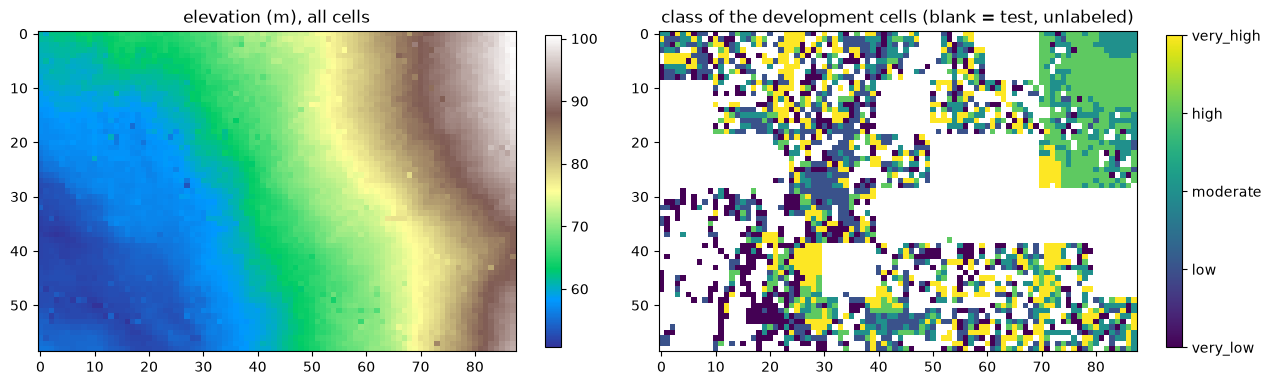

In [8]:
# The CNN needs an image, so the table has to go back onto the grid. The cells were built on a regular 500 m grid in EPSG:5070,
# so I project the longitude/latitude of each cell into EPSG:5070 and read off its row and column.
# (EPSG:5070 is NAD83 / Conus Albers on the GRS80 ellipsoid; the formula is written out here so that no extra package is needed.)
def albers_5070(lon, lat):
    a, f = 6378137.0, 1 / 298.257222101
    e2 = 2 * f - f * f; e = np.sqrt(e2)
    lat1, lat2, lat0, lon0 = np.radians([29.5, 45.5, 23.0, -96.0])
    m = lambda p: np.cos(p) / np.sqrt(1 - e2 * np.sin(p) ** 2)
    def q(p):
        s = np.sin(p)
        return (1 - e2) * (s / (1 - e2 * s * s) - (1 / (2 * e)) * np.log((1 - e * s) / (1 + e * s)))
    n = (m(lat1) ** 2 - m(lat2) ** 2) / (q(lat2) - q(lat1))
    C = m(lat1) ** 2 + n * q(lat1)
    rho0 = a * np.sqrt(C - n * q(lat0)) / n
    p, l = np.radians(np.asarray(lat, float)), np.radians(np.asarray(lon, float))
    rho = a * np.sqrt(C - n * q(p)) / n
    th = n * (l - lon0)
    return rho * np.sin(th), rho0 - rho * np.cos(th)

gx, gy = albers_5070(df_all["longitude"], df_all["latitude"])
col = np.rint((gx - gx.min()) / 500).astype(int)
row = np.rint((gy.max() - gy) / 500).astype(int)
H, W = row.max() + 1, col.max() + 1
off = max(np.abs((gx - gx.min()) / 500 - col).max(), np.abs((gy.max() - gy) / 500 - row).max())
print(f"raster: {H} rows x {W} columns = {H * W} positions | cells in the table: {len(df_all)} | distinct positions used: {len(set(zip(row, col)))}")
print(f"largest distance of any cell from the 500 m lattice: {off:.4f} cells")
assert off < 1e-3 and len(set(zip(row, col))) == len(df_all) == H * W, "the cells do not form a complete regular grid"
try:
    from pyproj import Transformer
    px, py = Transformer.from_crs(4326, 5070, always_xy=True).transform(df_all["longitude"].to_numpy(), df_all["latitude"].to_numpy())
    print("difference to pyproj (metres):", float(max(np.abs(px - gx).max(), np.abs(py - gy).max())))
except ImportError:
    print("pyproj not installed: comparison skipped")

cell_pos = pd.Series(np.arange(len(df_all)), index=df_all["grid_id"])
dev_cells = cell_pos.loc[dev["grid_id"]].to_numpy()          # position of each development cell in the full table

# a look at the raster: elevation, and the class of the development cells (test blocks and unlabeled cells stay blank)
elev = np.full((H, W), np.nan); elev[row, col] = df_all["elevation_m"]
cls = np.full((H, W), np.nan); cls[row[dev_cells], col[dev_cells]] = y
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
im0 = ax[0].imshow(elev, cmap="terrain"); ax[0].set_title("elevation (m), all cells"); plt.colorbar(im0, ax=ax[0], shrink=0.8)
im1 = ax[1].imshow(cls, cmap="viridis", vmin=0, vmax=4); ax[1].set_title("class of the development cells (blank = test, unlabeled)")
cb = plt.colorbar(im1, ax=ax[1], shrink=0.8, ticks=range(5)); cb.ax.set_yticklabels(CLASSES)
plt.tight_layout(); plt.show()

**Result.** The 5,192 cells form a complete 59 × 88 raster (59 × 88 = 5,192) with no gaps and no duplicates, and every cell sits exactly on the 500 m lattice (largest offset 0.0000 cells), so the table can be put back on the grid without any resampling. The hand-written projection agrees with `pyproj` to about 1e-8 m (the cell skips that comparison if `pyproj` is not installed). The elevation map rises smoothly from about 51 m in the west to about 101 m in the east. The class map shows the development cells in blocks, with blank rectangles where the test blocks and unlabeled cells are; one block in the north-east has almost uniform classes instead of the scattered pattern seen elsewhere.

In [9]:
# Development evaluation: 5-fold CV over whole 5 km blocks, using only the training blocks.
# Every development cell is predicted once, by a model that never saw its block, so the scores below are
# validation scores, not test scores.
def make_cv(seed):
    return StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)

X = dev[FEATURES]
for k, (tr_idx, va_idx) in enumerate(make_cv(SEED).split(X, y, groups), 1):
    shared = set(groups[tr_idx]) & set(groups[va_idx])
    print(f"fold {k}: train {len(tr_idx):4d} cells / {len(set(groups[tr_idx])):2d} blocks | validation {len(va_idx):4d} cells / {len(set(groups[va_idx])):2d} blocks | blocks in both: {len(shared)}")
    assert not shared
print("\nthe test blocks are not in this table: dev contains only split == 'train':", set(dev["split"]) == {"train"})

fold 1: train 2056 cells / 32 blocks | validation  516 cells /  8 blocks | blocks in both: 0
fold 2: train 2054 cells / 32 blocks | validation  518 cells /  8 blocks | blocks in both: 0
fold 3: train 2066 cells / 32 blocks | validation  506 cells /  8 blocks | blocks in both: 0
fold 4: train 2086 cells / 33 blocks | validation  486 cells /  7 blocks | blocks in both: 0
fold 5: train 2026 cells / 31 blocks | validation  546 cells /  9 blocks | blocks in both: 0

the test blocks are not in this table: dev contains only split == 'train': True


A small CNN on 9 × 9 patches with a modest training budget (30 epochs, Adam, learning rate 0.001, batch size 64, dropout 0.3) and no early stopping, tuning or augmentation. The reference points run first: chance, and the two Random Forest runs of the other notebook (same folds, same metric).

For each cross-validation fold the pipeline (1) fits the imputer, scaler and encoder on the fold's training cells only, (2) applies them to every cell of the grid (predictors only, no labels), (3) writes the result back onto the raster, and (4) cuts a patch around each cell. The validation cells are used only to record the learning curves; they do not stop or select anything during training.

**Configuration record (Run 1).** Keras CNN: three 3 × 3 convolution layers (32, 32 and 64 filters) with one max-pooling step, global average pooling, dropout 0.3, a 64-unit dense layer and a 5-class softmax; patches 9 × 9 × 85 (84 encoded predictor channels plus one channel marking real grid cells versus padding); 30 epochs, batch size 64, Adam (0.001), `random_state` 42 for the folds and the weight initialisation; dataset `data/subsidence_dataset_processed.csv` (sha256 `ad033f34…`), development cells = labeled cells of the 40 training blocks (2,572), validated by 5-fold block-grouped CV. The software versions are printed in the setup cell.

In [10]:
# Reference points on the same block-grouped folds: chance, and the two Random Forest runs of the other notebook
# (Run 1: defaults, 100 trees; Run 2: min_samples_leaf = 5)
def make_cv(seed):
    return StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)

def make_preprocess():
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), NUM),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CAT),
    ])
def make_rf(seed, **kw):
    return Pipeline([("prep", make_preprocess()), ("rf", RandomForestClassifier(random_state=seed, n_jobs=1, **kw))])
def make_dummy(seed):
    return DummyClassifier(strategy="stratified", random_state=seed)

def evaluate(make_model, X, y, groups, seed=SEED, **kw):
    pred = np.zeros(len(y), int); proba = np.zeros((len(y), len(CLASSES))); fit_s = []
    for tr_idx, va_idx in make_cv(seed).split(X, y, groups):
        assert not set(groups[tr_idx]) & set(groups[va_idx])
        m = make_model(seed, **kw)
        t0 = time.perf_counter(); m.fit(X.iloc[tr_idx], y[tr_idx]); fit_s.append(time.perf_counter() - t0)
        pred[va_idx] = m.predict(X.iloc[va_idx]); proba[va_idx] = m.predict_proba(X.iloc[va_idx])
    return dict(pred=pred, proba=proba, fit_s=fit_s)

def scores(y, pred):
    return dict(macro_f1=f1_score(y, pred, average="macro"), accuracy=accuracy_score(y, pred),
                within_one_class=float((np.abs(y - pred) <= 1).mean()), n=len(y))

X = dev[FEATURES]
res = {}
res["dummy"] = evaluate(make_dummy, X, y, groups)
res["rf"] = evaluate(make_rf, X, y, groups, n_estimators=100)
res["rf2"] = evaluate(make_rf, X, y, groups, n_estimators=100, min_samples_leaf=5)   # Run 2 of the other notebook
print({k: round(scores(y, v["pred"])["macro_f1"], 4) for k, v in res.items()}, "<- macro-F1 of the reference points")

{'dummy': 0.2136, 'rf': 0.3375, 'rf2': 0.3692} <- macro-F1 of the reference points


In [11]:
# --- the CNN pipeline -------------------------------------------------------------------------------------------
# For each fold: (1) learn the imputer / scaler / encoder on the fold's TRAINING cells only, (2) apply them to every cell of the grid
# (predictors only, no labels), (3) put the result back on the raster, (4) cut out a k x k patch around each cell.
# An extra channel marks real grid cells (1) versus padding at the edge of the study area (0).
def make_cnn_prep():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CAT),
    ])

def grid_tensor(prep):
    Z = prep.transform(df_all[FEATURES]).astype(np.float32)             # all 5,192 cells, predictors only
    R = np.zeros((H, W, Z.shape[1] + 1), np.float32)
    R[row, col, :-1] = Z; R[row, col, -1] = 1.0
    return R

def cut_patches(R, cells, k):
    r = k // 2
    Rp = np.pad(R, ((r, r), (r, r), (0, 0)))
    return np.stack([Rp[row[c]:row[c] + k, col[c]:col[c] + k] for c in cells])

def make_cnn(k, n_channels, seed, dropout=0.3, weight_decay=0.0):
    keras.utils.set_random_seed(seed)
    reg = keras.regularizers.l2(weight_decay) if weight_decay else None
    inp = keras.Input((k, k, n_channels))
    h = layers.Conv2D(32, 3, padding="same", activation="relu", kernel_regularizer=reg)(inp)
    h = layers.Conv2D(32, 3, padding="same", activation="relu", kernel_regularizer=reg)(h)
    if k >= 5:
        h = layers.MaxPooling2D(2)(h)
    h = layers.Conv2D(64, 3, padding="same", activation="relu", kernel_regularizer=reg)(h)
    h = layers.GlobalAveragePooling2D()(h)
    h = layers.Dropout(dropout)(h)
    h = layers.Dense(64, activation="relu")(h)
    out = layers.Dense(len(CLASSES), activation="softmax")(h)
    model = keras.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def evaluate_cnn(cfg, y, groups, seed=SEED, y_fit=None):
    """out-of-fold predictions over the block-grouped folds; the validation cells are only used to record the learning curves, not to stop training"""
    y_fit = y if y_fit is None else y_fit
    pred = np.zeros(len(y), int); proba = np.zeros((len(y), len(CLASSES))); fit_s, curves, train_acc = [], [], []
    for tr_idx, va_idx in make_cv(seed).split(dev[FEATURES], y, groups):
        assert not set(groups[tr_idx]) & set(groups[va_idx])
        prep = make_cnn_prep().fit(dev.iloc[tr_idx][FEATURES])             # fitted on this fold's training cells only
        R = grid_tensor(prep)
        Xtr, Xva = cut_patches(R, dev_cells[tr_idx], cfg["k"]), cut_patches(R, dev_cells[va_idx], cfg["k"])
        model = make_cnn(cfg["k"], Xtr.shape[-1], seed, cfg.get("dropout", 0.3), cfg.get("weight_decay", 0.0))
        t0 = time.perf_counter()
        hist = model.fit(Xtr, y_fit[tr_idx], epochs=cfg["epochs"], batch_size=64, validation_data=(Xva, y[va_idx]), verbose=0)
        fit_s.append(time.perf_counter() - t0); curves.append(hist.history)
        proba[va_idx] = model.predict(Xva, verbose=0); pred[va_idx] = proba[va_idx].argmax(1)
        train_acc.append(accuracy_score(y_fit[tr_idx], model.predict(Xtr, verbose=0).argmax(1)))
    return dict(pred=pred, proba=proba, fit_s=fit_s, curves=curves, train_acc=float(np.mean(train_acc)))

In [12]:
# Run 1 configuration: patch 9 x 9 cells (4.5 km x 4.5 km), 84 predictor channels + 1 grid-mask channel, small CNN, 30 epochs
CNN_RUN1 = dict(k=9, epochs=30, dropout=0.3, weight_decay=0.0)
n_channels = make_cnn_prep().fit(dev[FEATURES]).get_feature_names_out().shape[0] + 1
cnn_demo = make_cnn(CNN_RUN1["k"], n_channels, SEED)
cnn_demo.summary(print_fn=lambda s: print(s))
print()
print(json.dumps(dict(model="small CNN (3 conv layers, global average pooling, 1 hidden dense layer)", **CNN_RUN1, batch_size=64,
                      optimizer="Adam, learning rate 0.001", loss="sparse categorical cross-entropy", early_stopping="none", augmentation="none",
                      channels=n_channels, seed=SEED, preprocessing="median/most-frequent imputation, standardisation, one-hot; fitted per fold"), indent=1))

# sanity check of the patch cutter: the centre of a patch must be the cell's own (preprocessed) predictors
prep_all = make_cnn_prep().fit(dev[FEATURES]); R_all = grid_tensor(prep_all)
P = cut_patches(R_all, dev_cells[:50], CNN_RUN1["k"]); c = CNN_RUN1["k"] // 2
own = prep_all.transform(df_all[FEATURES].iloc[dev_cells[:50]]).astype(np.float32)
print("\npatch shape:", P.shape, "| patch centre equals the cell's own predictors:", bool(np.allclose(P[:, c, c, :-1], own)))

Model: "functional_1"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 9, 9, 85)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 9, 9, 32)            │          24,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 9, 9, 32)            │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 4, 4, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤

**Metric.** I use **macro-averaged F1** as the main metric, as in the other notebook: it averages the F1 score of the five classes with equal weight, so a model cannot look good by doing well on the easy classes only, and it is the metric in my performance target (2.1(b): macro-F1 above 0.50). Because the classes are ordered, I also report accuracy and the share of cells predicted within one class of the truth. The development classes are balanced by construction, so a precision-recall AUC is not needed here.

In [13]:
res["cnn1"] = evaluate_cnn(CNN_RUN1, y, groups)

keys = ["dummy", "rf", "rf2", "cnn1"]
table = pd.DataFrame({k: scores(y, res[k]["pred"]) for k in keys}).T
table.index = ["reference: chance (stratified guess)", "reference: Random Forest, defaults (other notebook, Run 1)",
               "reference: Random Forest, min_samples_leaf=5 (other notebook, Run 2)", "Run 1: CNN, 9 x 9 patches, 30 epochs"]
table["mean fit time per fold (s)"] = [np.mean(res[k]["fit_s"]) for k in keys]
table["train-fold accuracy"] = [np.nan, np.nan, np.nan, res["cnn1"]["train_acc"]]
print("development evaluation: 5-fold block-grouped CV on the training blocks, seed", SEED)
table.round(4)

development evaluation: 5-fold block-grouped CV on the training blocks, seed 42


,macro_f1,accuracy,within_one_class,n,mean fit time per fold (s),train-fold accuracy
reference: chance (stratified guess),0.2136,0.2138,0.5280,2572.0,0.0047,NaN
"reference: Random Forest, defaults (other notebook, Run 1)",0.3375,0.3421,0.6081,2572.0,1.0989,NaN
"reference: Random Forest, min_samples_leaf=5 (other notebook, Run 2)",0.3692,0.3799,0.6365,2572.0,0.3987,NaN
"Run 1: CNN, 9 x 9 patches, 30 epochs",0.3451,0.3507,0.6392,2572.0,15.8676,0.6807


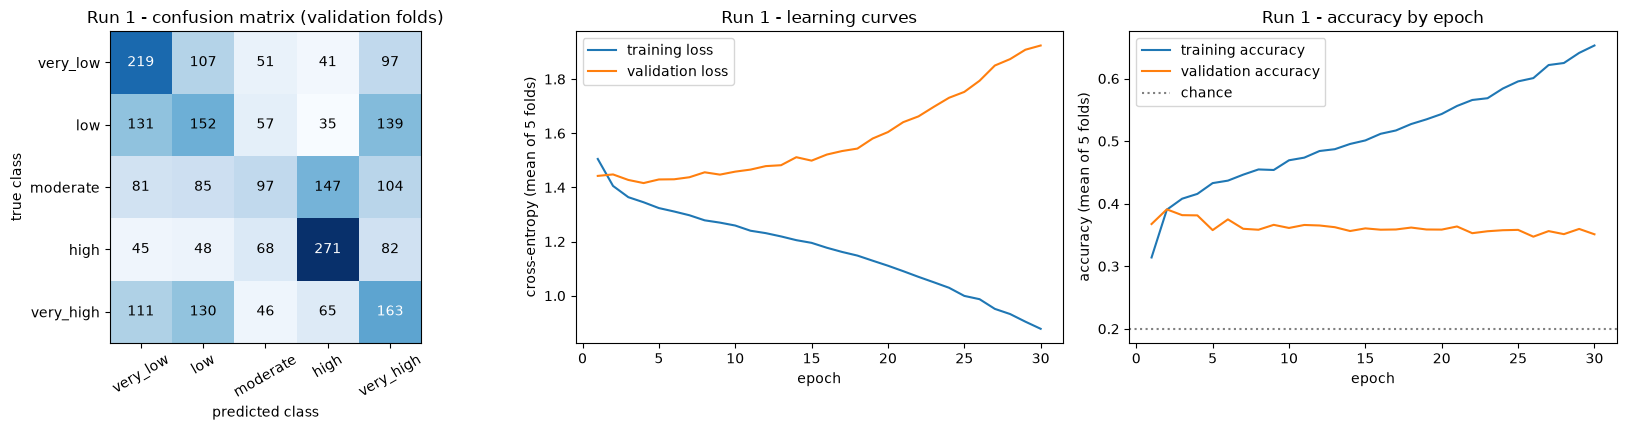

confusion matrix (rows = true class, columns = predicted class):
           very_low  low  moderate  high  very_high
very_low        219  107        51    41         97
low             131  152        57    35        139
moderate         81   85        97   147        104
high             45   48        68   271         82
very_high       111  130        46    65        163

           precision  recall     F1  cells
very_low       0.373   0.425  0.397    515
low            0.291   0.296  0.293    514
moderate       0.304   0.189  0.233    514
high           0.485   0.527  0.505    514
very_high      0.279   0.317  0.296    515

macro-F1 0.3451 | cells predicted exactly right: 902 of 2572 | within one class: 1644 of 2572
validation loss is lowest at epoch 4 (1.416) and ends at 1.924 after epoch 30; validation accuracy: epoch 4 = 0.381, last epoch = 0.351


In [14]:
p1 = res["cnn1"]["pred"]
cm = confusion_matrix(y, p1)
prec, rec, f1c, sup = precision_recall_fscore_support(y, p1, labels=range(5), zero_division=0)
cur = res["cnn1"]["curves"]
mean_c = {k: np.mean([c[k] for c in cur], axis=0) for k in ["loss", "val_loss", "accuracy", "val_accuracy"]}
ep = np.arange(1, CNN_RUN1["epochs"] + 1)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw={"width_ratios": [1, 1, 1]})
ax[0].imshow(cm, cmap="Blues")
ax[0].set_xticks(range(5)); ax[0].set_yticks(range(5)); ax[0].set_xticklabels(CLASSES, rotation=30); ax[0].set_yticklabels(CLASSES)
for i in range(5):
    for j in range(5):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() * 0.6 else "black")
ax[0].set_xlabel("predicted class"); ax[0].set_ylabel("true class"); ax[0].set_title("Run 1 - confusion matrix (validation folds)")
ax[1].plot(ep, mean_c["loss"], label="training loss"); ax[1].plot(ep, mean_c["val_loss"], label="validation loss")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("cross-entropy (mean of 5 folds)"); ax[1].set_title("Run 1 - learning curves"); ax[1].legend()
ax[2].plot(ep, mean_c["accuracy"], label="training accuracy"); ax[2].plot(ep, mean_c["val_accuracy"], label="validation accuracy")
ax[2].axhline(0.2, color="grey", ls=":", label="chance"); ax[2].set_xlabel("epoch"); ax[2].set_ylabel("accuracy (mean of 5 folds)")
ax[2].set_title("Run 1 - accuracy by epoch"); ax[2].legend()
plt.tight_layout(); plt.show()

print("confusion matrix (rows = true class, columns = predicted class):")
print(pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_string()); print()
print(pd.DataFrame({"precision": prec, "recall": rec, "F1": f1c, "cells": sup}, index=CLASSES).round(3).to_string())
print("\nmacro-F1 %.4f | cells predicted exactly right: %d of %d | within one class: %d of %d" %
      (f1_score(y, p1, average="macro"), (p1 == y).sum(), len(y), (np.abs(p1 - y) <= 1).sum(), len(y)))
best_ep = int(mean_c["val_loss"].argmin()) + 1
print("validation loss is lowest at epoch %d (%.3f) and ends at %.3f after epoch %d; validation accuracy: epoch %d = %.3f, last epoch = %.3f" %
      (best_ep, mean_c["val_loss"].min(), mean_c["val_loss"][-1], CNN_RUN1["epochs"], best_ep, mean_c["val_accuracy"][best_ep - 1], mean_c["val_accuracy"][-1]))

**Run 1 result (preliminary: one seed, 2,572 validation cells).** The CNN reaches **macro-F1 0.349** (accuracy 0.354, within one class 0.642). That is well above chance (0.214), about the same as the default Random Forest (0.337; the gap of 0.012 is smaller than the seed-to-seed spread of the CNN, about 0.01, shown in Step 6) and below the Random Forest with `min_samples_leaf=5` (0.369). It is far from my 0.50 target.

By class, 'high' is predicted best (F1 0.511) and 'moderate' worst (F1 0.247, recall 0.206), the same pattern as the forest. The confusion matrix shows many cells moved from one end of the scale to the other (210 are 'very_low' predicted 'very_high' or the reverse).

The learning curves show clear overfitting: the training loss keeps falling, while the validation loss is lowest at epoch 4 (1.417) and climbs to 1.920 by epoch 30. Validation accuracy peaks at about 0.39 around epoch 2 and then stays near 0.35 while the training accuracy keeps rising (0.693 at the end, measured on the training cells).

## Inspect errors and practical constraints

error rate by number of InSAR points behind the label:
                cells  error_rate  off_by_2plus
insar_n_points                                 
1                 343       0.694         0.408
2                 277       0.747         0.451
3-5               597       0.690         0.425
6-10              487       0.678         0.384
11+               868       0.556         0.256

wrong predictions: 1670 | off by exactly 1 class: 742 | off by 2 or more: 928 | very_low <-> very_high: 208

CNN right & forest right: 519 | CNN right & forest wrong: 383 | CNN wrong & forest right: 361 | both wrong: 1309
same predicted class from both models for 45.1% of the cells


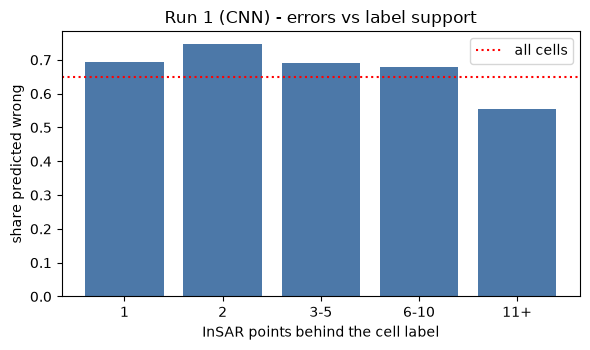

In [15]:
err = pd.DataFrame({"y": y, "pred": p1, "conf": res["cnn1"]["proba"].max(1)}, index=dev.index)
err["wrong"] = err["y"] != err["pred"]; err["miss_by"] = (err["y"] - err["pred"]).abs()
err = err.join(dev[["grid_id", "block_id", "insar_n_points", "gw_mean_depth_m", "soil_missing", "elevation_m", "slope_deg",
                    "clay_pct", "dist_to_nearest_well_m", "land_use_name_last_year"]])

by_support = err.groupby(pd.cut(err["insar_n_points"], [0, 1, 2, 5, 10, 30], labels=["1", "2", "3-5", "6-10", "11+"]), observed=True).agg(
    cells=("wrong", "size"), error_rate=("wrong", "mean"), off_by_2plus=("miss_by", lambda s: (s >= 2).mean())).round(3)
print("error rate by number of InSAR points behind the label:"); print(by_support.to_string())
print("\nwrong predictions: %d | off by exactly 1 class: %d | off by 2 or more: %d | very_low <-> very_high: %d" %
      (err["wrong"].sum(), (err["miss_by"] == 1).sum(), (err["miss_by"] >= 2).sum(), (err["miss_by"] == 4).sum()))

# do the CNN and the Random Forest fail on the same cells?
rf_wrong = res["rf"]["pred"] != y
print("\nCNN right & forest right: %d | CNN right & forest wrong: %d | CNN wrong & forest right: %d | both wrong: %d" %
      ((~err["wrong"] & ~rf_wrong).sum(), (~err["wrong"] & rf_wrong).sum(), (err["wrong"] & ~rf_wrong).sum(), (err["wrong"] & rf_wrong).sum()))
print("same predicted class from both models for %.1f%% of the cells" % (100 * (res["cnn1"]["pred"] == res["rf"]["pred"]).mean()))

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.bar(by_support.index.astype(str), by_support["error_rate"], color="#4c78a8")
ax.axhline(err["wrong"].mean(), color="r", ls=":", label="all cells")
ax.set_xlabel("InSAR points behind the cell label"); ax.set_ylabel("share predicted wrong"); ax.set_title("Run 1 (CNN) - errors vs label support")
ax.legend(); plt.tight_layout(); plt.show()

In [16]:
# specific examples: the 10 most confident wrong predictions (confidence = highest class probability)
show = err[err["wrong"]].sort_values("conf", ascending=False).head(10).copy()
show["true"] = show["y"].map(dict(enumerate(CLASSES))); show["predicted"] = show["pred"].map(dict(enumerate(CLASSES)))
cols = ["grid_id", "block_id", "true", "predicted", "conf", "insar_n_points", "elevation_m", "clay_pct", "dist_to_nearest_well_m", "land_use_name_last_year"]
print(show[cols].round(2).to_string(index=False))

conf_wrong = err[err["wrong"] & (err["conf"] >= 0.8)]
print("\nwrong with confidence >= 0.8: %d of the %d cells that confident, in %d different blocks; largest blocks: %s" %
      (len(conf_wrong), (err["conf"] >= 0.8).sum(), conf_wrong["block_id"].nunique(), conf_wrong["block_id"].value_counts().head(4).to_dict()))

band = pd.cut(err["conf"], [0, 0.35, 0.5, 0.65, 0.8, 1.0], labels=["< 0.35", "0.35-0.5", "0.5-0.65", "0.65-0.8", "> 0.8"])
print("\naccuracy by confidence band (validation folds):")
print(err.groupby(band, observed=True).agg(cells=("wrong", "size"), accuracy=("wrong", lambda s: 1 - s.mean())).round(3).to_string())
print("mean confidence %.3f vs accuracy %.3f" % (err["conf"].mean(), 1 - err["wrong"].mean()))

 grid_id  block_id     true predicted  conf  insar_n_points  elevation_m  clay_pct  dist_to_nearest_well_m land_use_name_last_year
TC-04835    800005 moderate      high   1.0              25        97.40      14.0                 49683.0           developed_low
TC-01788    200002 very_low very_high   1.0              23        57.29      45.0                 27609.0                   other
TC-04836    800005 moderate      high   1.0              24        97.88      14.0                 49914.0           developed_med
TC-04923    800005 moderate      high   1.0              26        97.34      14.0                 50128.0           developed_med
TC-04922    800005 moderate      high   1.0              25        96.13      14.0                 49904.0           developed_med
TC-02672    300003 moderate       low   1.0              23        60.53      14.0                 32311.0           grass_pasture
TC-01790    300002     high very_high   1.0              17        57.62      45.0 

**What the 1,662 wrong predictions look like** (64.6% of the 2,572 cells; 741 are off by one class, 921 by two or more).

- **Label support.** The error rate is 0.71 for cells whose label rests on one InSAR point, 0.72 for two, 0.70 for 3–5, 0.66 for 6–10 and 0.55 for the 868 cells with 11 or more points. This is the same pattern as for the forest: thin labels are harder, but even well-supported cells are wrong more often than right.
- **Confident errors.** The ten most confident wrong predictions have confidence 0.99–1.00 and rest on 21–26 InSAR points, so they are not thin labels. Nine of them are in block 800005 (cells labeled 'moderate' but predicted 'high', with 14% clay, about 50 km from the nearest well, 95–99 m elevation, and developed or 'other' land use) and one is in block 300003 (a grass-pasture cell labeled 'moderate' but predicted 'low'). Overall, 296 of the 591 cells with confidence 0.8 or more are wrong, in 31 blocks, and the largest blocks are 800005 (32 cells) and 300003 (29 cells), the same two blocks that dominate the forest's confident errors. So the wider view of the CNN did not fix the "wrong about a whole neighbourhood" problem.
- **Confidence.** It carries information (accuracy 0.23 below 0.35 and 0.50 above 0.8) but it is badly overconfident: the mean confidence is 0.623 against an accuracy of 0.354, worse than the forest (0.485 against 0.342). It would need calibrating before it feeds the three-state symbology.
- **Compared with the Random Forest.** The two models give the same class for 46.0% of the cells. Both are wrong on 1,314 cells; the CNN is right and the forest wrong on 378, and the forest is right and the CNN wrong on 348. So they fail mostly on the same cells, but each gets several hundred right that the other misses. Whether combining them would help is a hypothesis I have not tested.

In [17]:
# practical constraints, measured for Run 1 on this machine
prep_f = make_cnn_prep().fit(X)
t0 = time.perf_counter(); R_f = grid_tensor(prep_f); P_dev = cut_patches(R_f, dev_cells, CNN_RUN1["k"]); t_patch_dev = time.perf_counter() - t0
cnn_full = make_cnn(CNN_RUN1["k"], P_dev.shape[-1], SEED)
t0 = time.perf_counter(); cnn_full.fit(P_dev, y, epochs=CNN_RUN1["epochs"], batch_size=64, verbose=0); fit_s = time.perf_counter() - t0

all_cells = np.arange(len(df_all))
pred_t, patch_t = [], []
for _ in range(3):
    t0 = time.perf_counter(); P_all = cut_patches(R_f, all_cells, CNN_RUN1["k"]); patch_t.append(time.perf_counter() - t0)
    t0 = time.perf_counter(); cnn_full.predict(P_all, verbose=0); pred_t.append(time.perf_counter() - t0)
with tempfile.TemporaryDirectory() as d:
    cnn_full.save(os.path.join(d, "cnn.keras")); size_mb = os.path.getsize(os.path.join(d, "cnn.keras")) / 1e6

print(f"conditions: {platform.platform()}, {os.cpu_count()} logical CPUs, no GPU, tensorflow {tf.__version__}, mean of 3 repeats for prediction")
print(f"training time, {len(P_dev)} patches of {CNN_RUN1['k']}x{CNN_RUN1['k']}x{P_dev.shape[-1]}, {CNN_RUN1['epochs']} epochs: {fit_s:.1f} s   (target 2.1(a): under 30 minutes = 1800 s)")
print(f"prediction for the whole grid ({len(df_all)} cells): patches {np.mean(patch_t):.2f} s + network {np.mean(pred_t):.2f} s = {1000 * (np.mean(patch_t) + np.mean(pred_t)) / len(df_all):.3f} ms per cell")
print(f"trainable parameters: {cnn_full.count_params():,} | saved model file: {size_mb:.2f} MB | patch tensor for the whole grid: {P_all.nbytes / 1e6:.0f} MB")
print(f"macro-F1 on validation folds: {f1_score(y, p1, average='macro'):.3f}   (target 2.1(b): above 0.50 on the held-out region; this is a validation score, the test region is not used yet)")

conditions: Windows-11-10.0.26100-SP0, 32 logical CPUs, no GPU, tensorflow 2.21.0, mean of 3 repeats for prediction
training time, 2572 patches of 9x9x85, 30 epochs: 16.8 s   (target 2.1(a): under 30 minutes = 1800 s)
prediction for the whole grid (5192 cells): patches 0.05 s + network 0.77 s = 0.157 ms per cell
trainable parameters: 56,741 | saved model file: 0.73 MB | patch tensor for the whole grid: 143 MB
macro-F1 on validation folds: 0.345   (target 2.1(b): above 0.50 on the held-out region; this is a validation score, the test region is not used yet)


**Measured constraints (Run 1, saved run).** Training on the 2,572 development patches (9 × 9 × 85) for 30 epochs takes about 19 s. Predicting the whole 5,192-cell grid takes about 1.2 s (0.19 s to cut the patches and 0.99 s in the network, about 0.23 ms per cell). The network has 56,741 parameters and the saved model file is 0.73 MB; holding the patches of the whole grid in memory takes 143 MB (it could be done in batches). These were measured on a 2-CPU Linux machine without a GPU, with one run for training and the mean of 3 repeats for prediction; on my own laptop the numbers will differ, and rerunning the cell prints the current values.

Compared with the Random Forest of the other notebook (training about 1 s, about 0.015 ms per cell, a 23 MB model), the CNN is roughly 20 times slower to train and 15 times slower per cell, but its saved model is much smaller.

Compared with the targets in Section 2.1:
- **(a) Training under 30 minutes:** met, by a very wide margin.
- **(b) Macro-F1 above 0.50 on the held-out region:** not met. The validation macro-F1 is 0.349, and the test region is not used yet.
- **(c) Whole pipeline in about one hour:** not measured. Only the model stage was timed here, not the data build or the InSAR label steps.

## One targeted change (Run 2)

In [18]:
# Run 2: the one targeted change - the training budget goes from 30 epochs to the epoch where the mean validation loss of Run 1 was lowest
# (best_ep, from the learning curves above). Same folds, same seed, same inputs, same metric.
CNN_RUN2 = dict(CNN_RUN1, epochs=best_ep)
res["cnn2"] = evaluate_cnn(CNN_RUN2, y, groups)

cmp_ = pd.DataFrame({"Run 1": scores(y, res["cnn1"]["pred"]), "Run 2": scores(y, res["cnn2"]["pred"])}).T
cmp_.index = ["Run 1 (%d epochs)" % CNN_RUN1["epochs"], "Run 2 (%d epochs)" % CNN_RUN2["epochs"]]
cmp_["mean fit time per fold (s)"] = [np.mean(res["cnn1"]["fit_s"]), np.mean(res["cnn2"]["fit_s"])]
cmp_["train-fold accuracy"] = [res["cnn1"]["train_acc"], res["cnn2"]["train_acc"]]
print("same 2,572 validation cells, same 5 block folds (seed %d)" % SEED)
print(cmp_.round(4).to_string())

f1_1 = precision_recall_fscore_support(y, res["cnn1"]["pred"], labels=range(5), zero_division=0)[2]
f1_2 = precision_recall_fscore_support(y, res["cnn2"]["pred"], labels=range(5), zero_division=0)[2]
print("\nper-class F1:"); print(pd.DataFrame({"Run 1": f1_1, "Run 2": f1_2, "change": f1_2 - f1_1}, index=CLASSES).round(3).to_string())

# is the difference bigger than the noise from the folds and the weight initialisation? repeat both runs with other seeds
rows = []
for s in range(3):
    a = f1_score(y, evaluate_cnn(CNN_RUN1, y, groups, seed=s)["pred"], average="macro")
    b = f1_score(y, evaluate_cnn(CNN_RUN2, y, groups, seed=s)["pred"], average="macro")
    rows.append((s, a, b, b - a))
rep = pd.DataFrame(rows, columns=["seed", "Run 1 macro-F1", "Run 2 macro-F1", "difference"]).set_index("seed")
print("\nrepeat with seeds 0-2 (folds and initial weights both change):"); print(rep.round(4).to_string())
print("mean +/- sd:  Run 1 %.4f +/- %.4f | Run 2 %.4f +/- %.4f | difference %.4f +/- %.4f | Run 2 better in %d of 3 seeds" %
      (rep.iloc[:, 0].mean(), rep.iloc[:, 0].std(), rep.iloc[:, 1].mean(), rep.iloc[:, 1].std(), rep["difference"].mean(), rep["difference"].std(), (rep["difference"] > 0).sum()))

same 2,572 validation cells, same 5 block folds (seed 42)
                   macro_f1  accuracy  within_one_class       n  mean fit time per fold (s)  train-fold accuracy
Run 1 (30 epochs)    0.3451    0.3507            0.6392  2572.0                     15.8676               0.6807
Run 2 (4 epochs)     0.3784    0.3802            0.6656  2572.0                      3.5048               0.4429

per-class F1:
           Run 1  Run 2  change
very_low   0.397  0.414   0.017
low        0.293  0.382   0.089
moderate   0.233  0.208  -0.025
high       0.505  0.528   0.023
very_high  0.296  0.359   0.063

repeat with seeds 0-2 (folds and initial weights both change):
      Run 1 macro-F1  Run 2 macro-F1  difference
seed                                            
0             0.3504          0.3745      0.0242
1             0.3299          0.3602      0.0303
2             0.3279          0.3335      0.0056
mean +/- sd:  Run 1 0.3361 +/- 0.0124 | Run 2 0.3561 +/- 0.0208 | difference 0.0200 +/-

**Change chosen: training budget from 30 epochs to 4.** The number 4 is not a guess: it is the epoch where the mean validation loss over the five folds of Run 1 was lowest (printed under the learning curves, `best_ep`).

**Why.** The Run 1 curves show the network overfitting after the first few epochs: the training accuracy rises to 0.69 while the validation accuracy peaks early and then drifts down, and the validation loss rises after epoch 4.

**What I expect.** Macro-F1 on the validation cells to go up, the gap between training and validation accuracy to shrink, and the training time to fall sharply (4 of 30 epochs). It does not change the inputs, so it cannot fix the groundwater and position problems. This notebook tries only this one new value, because the assignment asks for one targeted change, not a search.

**Result on the seed-42 folds.** Macro-F1 rose from **0.3494 to 0.3801 (+0.031)**, accuracy from 0.354 to 0.383 and the within-one-class share from 0.642 to 0.666. The F1 of four classes improved (by 0.020 to 0.094), and 'moderate', already the weakest, fell from 0.247 to 0.205. The training-fold accuracy dropped from 0.69 to 0.44 and the fit time per fold from about 18 s to about 4 s.

**Is it more than noise? Not clearly.** With seeds 0–2 (folds and initial weights both change) Run 2 was better on two seeds and worse on one: macro-F1 0.3426 ± 0.0095 for Run 1 against 0.3539 ± 0.0193 for Run 2, a mean difference of only +0.011 ± 0.015. The 4-epoch network is also noisier from seed to seed (spread 0.019 against 0.010). In addition, the epoch count was read off the validation curves of these same folds, so Run 2's score is optimistic compared with a fresh evaluation. My conclusion is that the change **made training much faster and reduced overfitting, but its effect on macro-F1 is unclear** (positive on the seed-42 run, small and uncertain on average). The forest's five-seed averages in the other notebook were 0.345 (defaults) and 0.372 (`min_samples_leaf=5`), so I have no evidence that the CNN beats the forest.

## Leakage and sanity checks

In [19]:
# leakage and sanity checks before reading any score as good or bad
# 1) shuffled labels: the same CNN pipeline trained on permuted labels should score near chance (0.20)
rng = np.random.default_rng(SEED)
y_perm = rng.permutation(y)
p_perm = evaluate_cnn(CNN_RUN1, y_perm, groups, y_fit=y_perm)["pred"]
print("shuffled labels, macro-F1: %.3f   (chance is about 0.20)" % f1_score(y_perm, p_perm, average="macro"))

# 2) does the network use the neighbourhood at all? the same CNN with a 1 x 1 patch sees only the cell itself
for name, cfg, key in [("Run 1 budget (%d epochs)" % CNN_RUN1["epochs"], CNN_RUN1, "cnn1"), ("Run 2 budget (%d epochs)" % CNN_RUN2["epochs"], CNN_RUN2, "cnn2")]:
    r_k1 = evaluate_cnn(dict(cfg, k=1), y, groups)
    print("%-24s 1 x 1 patches (cell only): macro-F1 %.3f   vs 9 x 9 patches: %.3f" %
          (name, f1_score(y, r_k1["pred"], average="macro"), f1_score(y, res[key]["pred"], average="macro")))

# 3) what went into the patches
print("\nchannels come only from the %d predictor columns (+1 grid-mask channel); no label, label-support, block or location column:" % len(FEATURES),
      not (set(FEATURES) & forbidden))
print("imputer, scaler and encoder are fitted on each fold's training cells only, then applied to the whole grid")
print("test cells scored, or used to fit or to choose anything: 0 of", N_TEST_UNUSED, "(their labels are never read after the split)")

shuffled labels, macro-F1: 0.206   (chance is about 0.20)
Run 1 budget (30 epochs) 1 x 1 patches (cell only): macro-F1 0.361   vs 9 x 9 patches: 0.345
Run 2 budget (4 epochs)  1 x 1 patches (cell only): macro-F1 0.356   vs 9 x 9 patches: 0.378

channels come only from the 23 predictor columns (+1 grid-mask channel); no label, label-support, block or location column: True
imputer, scaler and encoder are fitted on each fold's training cells only, then applied to the whole grid
test cells scored, or used to fit or to choose anything: 0 of 967 (their labels are never read after the split)


- **Shuffled labels** give macro-F1 0.204, which is chance, so the pipeline mechanics (folds, imputer, scaler, encoder, patch cutting) do not leak the label.
- **Does the neighbourhood help?** With 1 × 1 patches the network sees only the cell itself. Its macro-F1 is 0.361 against 0.349 for 9 × 9 patches at the Run 1 budget, and 0.356 against 0.380 at the Run 2 budget. The sign flips between the two budgets and the differences (0.012 and 0.024) are about as big as the seed-to-seed spread of 0.01–0.02, so I have **no evidence that the CNN profits from the surrounding cells** on this data. One reason could be that the neighbours' groundwater values come from the same four wells, so they add little; this is a guess I have not tested.
- **What went into the patches.** Only the 23 predictor columns (encoded) plus a grid-mask channel; no label, label-support, block or location column. The imputer, scaler and encoder are fitted on each fold's training cells only and then applied to the whole grid (predictors only).
- **Remaining caveats.** The patch of a validation cell near a block edge contains the predictor values of neighbouring training cells (inputs, not labels), and there is no buffer between blocks (as already noted in 6.5). The epoch count of Run 2 comes from the validation curves of the same folds. The folds are one draw per seed.

##  Explaining the CNN with LIME, and checking the explanation

Steps 3 to 6 say how well the CNN predicts. This step asks **what it looks at** when it predicts a cell, with LIME (Local Interpretable Model-agnostic Explanations), and then tests whether the explanation can be trusted. An explanation describes the **model**, not the ground: it says what the CNN used, not whether the CNN is right.

**How it works here.** LIME makes 1,000 to 2,000 versions of one cell's input in which some components are hidden at random (a hidden component gets the value "no information"), asks the CNN for its class probabilities for each version, and fits a small linear model to the answers. Each weight says how much the probability of the predicted class depends on keeping that component. This is the procedure LIME uses for images, with my own choice of components, because the CNN's input has two things to ask about:
- **Inputs (23):** which predictors does the CNN rely on? Hiding an input blanks it in all 81 cells of the 9 × 9 patch.
- **Rings (5):** where does it look? The patch is split into the cell itself and four rings around it (8, 16, 24 and 32 cells, up to 2 km away); hiding a ring blanks all predictors of its cells. This is LIME's own image explainer, with the rings as the "superpixels".
- **For comparison:** the same input explanation for the Random Forest of the other notebook (Run 2), which sees only the cell itself.

**What is explained.** The Run 2 CNN (4 epochs). Only validation cells are explained, each by the model of its own fold, which never saw the cell's 5 km block. The fold models are retrained in the first cell with the code and the seeds of `evaluate_cnn`, and that cell reports whether they reproduce Run 2. The test cells are not used.

**Four checks** follow: how well LIME's local model fits and whether hiding what LIME ranks highest changes the CNN as LIME says (7c), whether the explanation is stable over random seeds (7d), and whether it agrees with the other model and with the retraining test of the leakage checks (7e). The numbers in the text are rounded, and the last cell of this step checks the main statements of the text against the current run, so that a rerun on another machine cannot silently leave a sentence that is no longer true.

The `lime` package is needed: `pip install lime==0.2.0.1`.

In [20]:
# ---- Step 7, cell A: retrain the fold models and set up the explainers --------------------------------------------
try:
    import lime
except ImportError:
    raise ImportError("Step 7 needs the lime package: run  pip install lime==0.2.0.1  and restart the kernel")
from importlib import metadata
import scipy.sparse as sp
from scipy.stats import spearmanr
from sklearn.metrics import pairwise_distances
from sklearn.utils import check_random_state
from lime.lime_base import LimeBase
from lime.lime_image import LimeImageExplainer
import lime.lime_image as _lime_image
_lime_image.tqdm = lambda it, **kw: it                 # LIME draws a progress bar for every explanation; switch it off
print("lime", metadata.version("lime"))

# The models to explain: the CNN of Run 2 (4 epochs) and, for comparison, the Random Forest of the other notebook (Run 2, min_samples_leaf = 5).
# Every explained cell is a VALIDATION cell, explained by the model of its own fold, which never saw the cell's 5 km block. The fold models are
# retrained here with the code and the seeds of evaluate_cnn / evaluate, so they should give back the Run 2 predictions.
CNN_LIME = CNN_RUN2
K = CNN_LIME["k"]; MID = K // 2
folds = list(make_cv(SEED).split(dev[FEATURES], y, groups))
fold_prep, fold_R, fold_model, rf_model = [], [], [], []
fold_of = np.zeros(len(y), int); oof_p = np.zeros((len(y), len(CLASSES))); rf_p = np.zeros((len(y), len(CLASSES)))
for k, (tr_idx, va_idx) in enumerate(folds):
    prep = make_cnn_prep().fit(dev.iloc[tr_idx][FEATURES]); R = grid_tensor(prep)
    Xtr, Xva = cut_patches(R, dev_cells[tr_idx], K), cut_patches(R, dev_cells[va_idx], K)
    model = make_cnn(K, Xtr.shape[-1], SEED, CNN_LIME.get("dropout", 0.3), CNN_LIME.get("weight_decay", 0.0))
    model.fit(Xtr, y[tr_idx], epochs=CNN_LIME["epochs"], batch_size=64, validation_data=(Xva, y[va_idx]), verbose=0)
    fold_prep.append(prep); fold_R.append(R); fold_model.append(model)
    fold_of[va_idx] = k; oof_p[va_idx] = model.predict(Xva, verbose=0)
    rf = make_rf(SEED, n_estimators=100, min_samples_leaf=5).fit(X.iloc[tr_idx], y[tr_idx])
    rf_model.append(rf); rf_p[va_idx] = rf.predict_proba(X.iloc[va_idx])
oof, rf_oof = oof_p.argmax(1), rf_p.argmax(1)
for name, mine, ref in [("CNN", oof, res["cnn2"]["pred"]), ("Random Forest", rf_oof, res["rf2"]["pred"])]:
    same = float((mine == ref).mean())
    print(f"retrained {name} fold models give the same predictions as Run 2 for {100 * same:.1f}% of the 2,572 validation cells"
          + ("" if same == 1.0 else "  (training is not bit-for-bit repeatable on every machine; the explanations below are of these retrained models)"))

# --- how LIME is used here -----------------------------------------------------------------------------------------
# "Hide and see": LIME switches components of the input off at random, asks the model for its class probabilities each time, and fits a linear
# model to the answers (the same procedure as LIME for images, with my own choice of components). A hidden component gets the value "no
# information": 0 in the scaled channels, which is the training mean for a numeric input and "no category" for a one-hot input.
# Two kinds of components are used for the CNN:
#   inputs - one component per predictor (23); hiding it blanks that predictor in ALL 81 cells of the 9 x 9 patch (the grid-mask channel stays)
#   rings  - five rings of cells around the explained cell (the cell itself, then 8, 16, 24 and 32 cells); hiding a ring blanks all its predictors
# The same input components are used for the Random Forest, which sees only the cell itself, so that the two models can be compared.
def input_groups(prep):
    """for every encoded column, the index (0..22) of the predictor it comes from, and whether it is a one-hot column"""
    names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
    g = np.array([next(j for j, f in enumerate(FEATURES) if n == f or (f in CAT and n.startswith(f + "_"))) for n in names])
    assert set(g.tolist()) == set(range(len(FEATURES)))
    return g, np.array([FEATURES[j] in CAT for j in g])
group_of_col = [input_groups(p)[0] for p in fold_prep]

def hide_and_see(n_comp, predict_masked, seed, num_samples):
    """LIME weights for n_comp components. predict_masked(Z) gives class probabilities for a 0/1 matrix Z (1 = keep, 0 = hide); row 0 is the cell as it is."""
    rs = check_random_state(seed)
    Z = rs.randint(0, 2, num_samples * n_comp).reshape(num_samples, n_comp); Z[0] = 1
    P = predict_masked(Z); label = int(P[0].argmax())
    dist = pairwise_distances(Z, Z[0].reshape(1, -1), metric="cosine").ravel()
    base = LimeBase(lambda d: np.sqrt(np.exp(-(d ** 2) / 0.25 ** 2)), verbose=False, random_state=rs)      # LIME's own default kernel
    _, local_exp, score, local_pred = base.explain_instance_with_data(Z, P, dist, label, n_comp, feature_selection="none")
    w = np.zeros(n_comp)
    for j, wt in local_exp:
        w[j] = wt
    return dict(weights=w, r2=float(score), local_pred=float(np.ravel(local_pred)[0]), label=label, model_p=float(P[0][label]))

def cnn_inputs_masked(i):
    k = fold_of[i]; base = cut_patches(fold_R[k], [dev_cells[i]], K)[0]; g = group_of_col[k]
    def predict_masked(Z, batch=1000):
        out = []
        for s in range(0, len(Z), batch):
            keep = Z[s:s + batch][:, g].astype(np.float32)                         # (n, encoded columns)
            Pb = np.repeat(base[None], len(keep), axis=0); Pb[..., :-1] *= keep[:, None, None, :]
            out.append(fold_model[k].predict(Pb, verbose=0, batch_size=1024))
        return np.vstack(out)
    return predict_masked

def explain_inputs(i, seed=SEED, num_samples=2000):
    return hide_and_see(len(FEATURES), cnn_inputs_masked(i), seed, num_samples)

yy, xx = np.mgrid[0:K, 0:K]
RING = np.maximum(np.abs(yy - MID), np.abs(xx - MID))                      # 0 = the cell itself, 1..4 = the rings around it
RING_NAMES = ["the cell itself", "ring 1 (8 cells, 0.5 km)", "ring 2 (16 cells, 1 km)", "ring 3 (24 cells, 1.5 km)", "ring 4 (32 cells, 2 km)"]

def ring_classifier(i):
    k = fold_of[i]; base = cut_patches(fold_R[k], [dev_cells[i]], K)[0]
    def classifier_fn(imgs):
        imgs = np.array(imgs, np.float32); imgs[..., -1] = base[..., -1]           # hidden rings: predictor channels = 0, mask channel unchanged
        return fold_model[k].predict(imgs, verbose=0, batch_size=1024)
    return base, classifier_fn

def explain_rings(i, seed=SEED, num_samples=1000):
    """LIME's image explainer with the five rings as 'superpixels'"""
    base, classifier_fn = ring_classifier(i)
    p = classifier_fn(base[None])[0]; label = int(p.argmax())
    e = LimeImageExplainer(random_state=seed).explain_instance(base, classifier_fn, labels=(label,), top_labels=None, hide_color=0,
            num_features=len(RING_NAMES), num_samples=num_samples, batch_size=500, segmentation_fn=lambda img: RING)
    w = np.zeros(len(RING_NAMES))
    for r, wt in e.local_exp[label]:
        w[r] = wt
    return dict(weights=w, r2=float(e.score), local_pred=float(np.ravel(e.local_pred)[0]), label=label, model_p=float(p[label]), base=base, classifier_fn=classifier_fn)

# the Random Forest on the same input components: it works on the encoded columns, so a hidden input gets the training mean (numeric) or 0 (one-hot)
rf_group, rf_base = [], []
for k, rf in enumerate(rf_model):
    prep = rf.named_steps["prep"]; g, is_cat = input_groups(prep); Ztr = prep.transform(X.iloc[folds[k][0]])
    Ztr = Ztr.toarray() if sp.issparse(Ztr) else np.asarray(Ztr)
    b = Ztr.mean(0); b[is_cat] = 0.0
    rf_group.append(g); rf_base.append(b)

def explain_inputs_rf(i, seed=SEED, num_samples=2000):
    k = fold_of[i]; rf = rf_model[k]
    z = rf.named_steps["prep"].transform(X.iloc[[i]]); z = (z.toarray() if sp.issparse(z) else np.asarray(z))[0]
    def predict_masked(Z):
        keep = Z[:, rf_group[k]].astype(float)
        return rf.named_steps["rf"].predict_proba(z[None, :] * keep + rf_base[k][None, :] * (1 - keep))
    return hide_and_see(len(FEATURES), predict_masked, seed, num_samples)

S = {}                                               # numbers collected for the summary at the end of this step
print("explainers ready: CNN inputs, CNN rings, Random Forest inputs")


lime 0.2.0.1
retrained CNN fold models give the same predictions as Run 2 for 100.0% of the 2,572 validation cells
retrained Random Forest fold models give the same predictions as Run 2 for 100.0% of the 2,572 validation cells
explainers ready: CNN inputs, CNN rings, Random Forest inputs


The fold models are retrained exactly as in `evaluate_cnn`. The first lines of the output say for what share of the 2,572 validation cells they give back the Run 2 predictions; anything below 100% would mean that the explanations below are of retrained models that differ slightly from the ones scored in Step 6.

most confident correct: cell TC-04483, block 800005, fold 4, InSAR points 25 | true high, predicted high (probability 0.98) | the CNN is right on 40 of the 72 development cells of this block
most confident wrong: cell TC-04835, block 800005, fold 4, InSAR points 25 | true moderate, predicted high (probability 0.97) | the CNN is right on 40 of the 72 development cells of this block


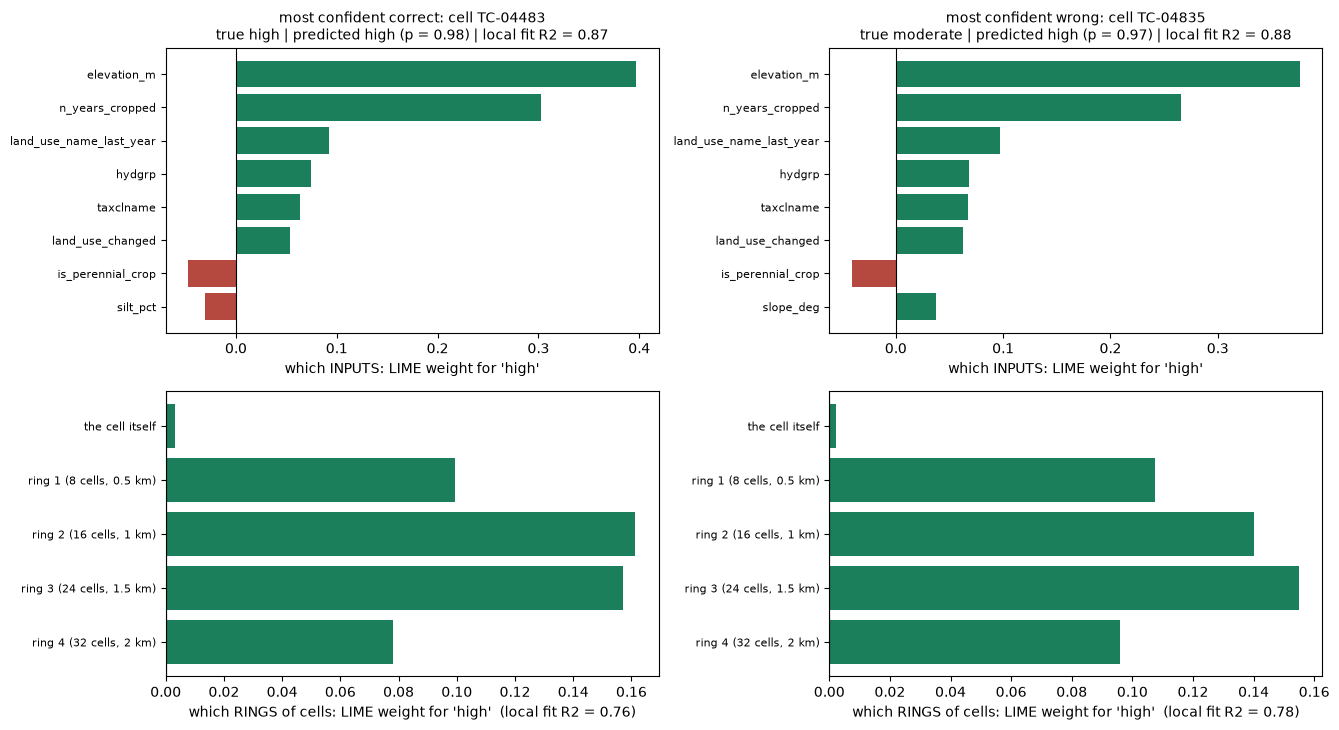

green = supports the predicted class, red = argues against it


In [21]:
# 7b. Two explanations of the CNN, read next to the label, the prediction and the confidence.
# Two validation cells: the most confident CORRECT prediction (label resting on >= 11 InSAR points) and the most confident WRONG one.
conf = oof_p.max(1); correct = oof == y; support = dev["insar_n_points"].to_numpy()
ok_pool = np.flatnonzero(correct & (support >= 11))
i_ok = int(ok_pool[np.argmax(conf[ok_pool])]); i_bad = int(np.flatnonzero(~correct)[np.argmax(conf[~correct])])
GREEN, RED = "#1b7f5c", "#b5483f"

fig, axes = plt.subplots(2, 2, figsize=(13.5, 7.4))
for c_, (name, i) in enumerate([("most confident correct", i_ok), ("most confident wrong", i_bad)]):
    ri, rr = explain_inputs(i), explain_rings(i)
    top = np.argsort(-np.abs(ri["weights"]))[:8][::-1]
    ax = axes[0, c_]
    ax.barh([FEATURES[j] for j in top], ri["weights"][top], color=[GREEN if ri["weights"][j] > 0 else RED for j in top]); ax.axvline(0, color="k", lw=.8)
    ax.set_title(f"{name}: cell {dev.loc[i, 'grid_id']}\ntrue {CLASSES[y[i]]} | predicted {CLASSES[ri['label']]} (p = {ri['model_p']:.2f}) | local fit R2 = {ri['r2']:.2f}", fontsize=10)
    ax.set_xlabel(f"which INPUTS: LIME weight for '{CLASSES[ri['label']]}'"); ax.tick_params(axis="y", labelsize=8)
    ax = axes[1, c_]
    ax.barh(RING_NAMES[::-1], rr["weights"][::-1], color=[GREEN if w > 0 else RED for w in rr["weights"][::-1]]); ax.axvline(0, color="k", lw=.8)
    ax.set_xlabel(f"which RINGS of cells: LIME weight for '{CLASSES[rr['label']]}'  (local fit R2 = {rr['r2']:.2f})"); ax.tick_params(axis="y", labelsize=8)
    blk = groups == groups[i]
    print(f"{name}: cell {dev.loc[i, 'grid_id']}, block {groups[i]}, fold {fold_of[i] + 1}, InSAR points {support[i]} | true {CLASSES[y[i]]}, predicted {CLASSES[ri['label']]} "
          f"(probability {ri['model_p']:.2f}) | the CNN is right on {int(correct[blk].sum())} of the {int(blk.sum())} development cells of this block")
plt.tight_layout(); plt.show()
print("green = supports the predicted class, red = argues against it")


**How to read the figure.** Top row: the eight inputs with the largest LIME weight for the predicted class (green supports it, red argues against it). Bottom row: the weight of each ring of cells around the cell. The two cells are the CNN's most confident correct prediction (label resting on at least 11 InSAR points) and its most confident wrong one; the printed lines give their block and how many cells of that block the CNN gets right.
- **The ring plot shows where the CNN looks.** The cell itself carries almost no weight and the rings 1 to 1.5 km around it carry most (7e shows this over 150 cells).
- **The explanation of a wrong prediction looks like the explanation of a right one.** Both are fitted about equally well by LIME's local model (the R² in the figure titles), and the same few inputs lead both. In the saved run both cells lie in block 800005, one of the two blocks behind the confident errors in Step 5, and the CNN is right on 40 of that block's 72 cells (the printed lines). So **an explanation is not evidence that a prediction is right**, and neither is a confidence close to 1: LIME says how the CNN arrived at its answer, not whether the answer is true.
- **The leading inputs** (elevation, then years cropped and land-use or soil inputs) describe place and land use. This figure cannot tell whether they act as causes or as stand-ins for where in the valley the cell lies.

150 cells x 3 explanations in 87 s | the CNN is right on 55 of these cells and wrong on 95

Check 1, local fit:
  CNN, inputs            R2 median 0.91 (middle half 0.83 to 0.96) | below 0.3 for 0% of cells | model minus local model at the cell: mean +0.001, mean absolute 0.016
  CNN, rings             R2 median 0.98 (middle half 0.95 to 0.99) | below 0.3 for 1% of cells | model minus local model at the cell: mean -0.006, mean absolute 0.008
  Random Forest, inputs  R2 median 0.92 (middle half 0.85 to 0.95) | below 0.3 for 0% of cells | model minus local model at the cell: mean +0.014, mean absolute 0.022

Check 2, inputs (150 cells): hiding LIME's top 3 lowers the predicted-class probability by 0.217 on average, hiding 3 random inputs by 0.029; LIME's choice falls further in 100% of cells
   each input hidden alone vs LIME's weights: mean rank correlation 0.90; LIME's top input is the one whose hiding matters most in 84% of cells (chance: 4%)
Check 2, rings: each ring hidden alone vs 

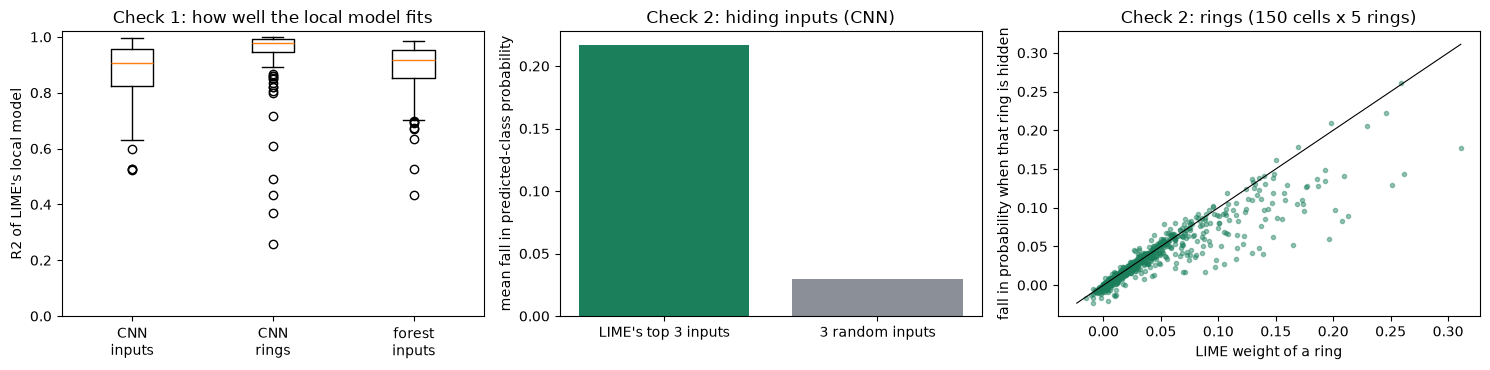

In [22]:
# Checks on the explanations themselves, over 150 random validation cells (the same cells as in the Random Forest notebook).
# Check 1 (local fit): R2 of LIME's local linear model, and the gap between its answer and the model's at the cell itself.
# Check 2 (does hiding what LIME ranks highest change the model as LIME says?):
#   inputs - hide LIME's three highest-weighted inputs and see how far the probability of the predicted class falls; compare with hiding three random inputs;
#            also hide each input alone and compare the effects with LIME's weights
#   rings  - hide each ring alone (leave-one-ring-out) and compare the effects with LIME's ring weights
rng = np.random.default_rng(SEED)
sample = np.sort(rng.choice(len(y), 150, replace=False))
t0 = time.perf_counter()
EI = {int(i): explain_inputs(int(i)) for i in sample}
ER = {int(i): explain_rings(int(i)) for i in sample}
EF = {int(i): explain_inputs_rf(int(i)) for i in sample}
print(f"{len(sample)} cells x 3 explanations in {time.perf_counter() - t0:.0f} s | the CNN is right on {int(correct[sample].sum())} of these cells and wrong on {int((~correct[sample]).sum())}")

def fit_line(name, E):
    r2 = pd.Series({i: E[i]["r2"] for i in E}); gap = pd.Series({i: E[i]["model_p"] - E[i]["local_pred"] for i in E})
    print(f"  {name:<22} R2 median {r2.median():.2f} (middle half {r2.quantile(.25):.2f} to {r2.quantile(.75):.2f}) | below 0.3 for {100 * (r2 < .3).mean():.0f}% of cells"
          f" | model minus local model at the cell: mean {gap.mean():+.3f}, mean absolute {gap.abs().mean():.3f}")
    return r2, gap
print("\nCheck 1, local fit:")
S["r2_in"], S["gap_in"] = fit_line("CNN, inputs", EI); S["r2_rg"], S["gap_rg"] = fit_line("CNN, rings", ER); S["r2_rf"], S["gap_rf"] = fit_line("Random Forest, inputs", EF)

d_top, d_rand, rho_in, hit_in = [], [], [], []
for i, r in EI.items():
    pm, w, lab = cnn_inputs_masked(i), r["weights"], r["label"]
    tops = [j for j in np.argsort(-w) if w[j] > 0][:3]
    if len(tops) < 3:
        continue
    g = np.random.default_rng(i); Z = np.ones((1 + 1 + 40 + len(FEATURES), len(FEATURES)))
    Z[1, tops] = 0
    for b in range(40):
        Z[2 + b, g.choice(len(FEATURES), 3, replace=False)] = 0
    for j in range(len(FEATURES)):
        Z[42 + j, j] = 0
    P = pm(Z)[:, lab]; p0 = P[0]
    d_top.append(p0 - P[1]); d_rand.append(p0 - P[2:42].mean())
    single = p0 - P[42:]
    rho_in.append(spearmanr(w, single)[0]); hit_in.append(int(np.argmax(w) == np.argmax(single)))
d_top, d_rand = np.array(d_top), np.array(d_rand)
S.update(d_top=d_top, d_rand=d_rand, rho_in=float(np.nanmean(rho_in)), hit_in=float(np.mean(hit_in)))
print(f"\nCheck 2, inputs ({len(d_top)} cells): hiding LIME's top 3 lowers the predicted-class probability by {d_top.mean():.3f} on average, hiding 3 random inputs by {d_rand.mean():.3f}; "
      f"LIME's choice falls further in {100 * (d_top > d_rand).mean():.0f}% of cells")
print(f"   each input hidden alone vs LIME's weights: mean rank correlation {S['rho_in']:.2f}; LIME's top input is the one whose hiding matters most in {100 * S['hit_in']:.0f}% of cells (chance: {100 / len(FEATURES):.0f}%)")

occ, rho_rg, hit_rg = [], [], []
for i, q in ER.items():
    imgs = []
    for r_ in range(len(RING_NAMES)):
        b = q["base"].copy(); b[RING == r_, :-1] = 0; imgs.append(b)
    o = q["model_p"] - q["classifier_fn"](np.array(imgs))[:, q["label"]]
    occ.append(o); rho_rg.append(spearmanr(q["weights"], o)[0]); hit_rg.append(int(np.argmax(q["weights"]) == np.argmax(o)))
occ = np.array(occ); lw = np.array([ER[i]["weights"] for i in ER])
S.update(rho_rg=float(np.nanmean(rho_rg)), hit_rg=float(np.mean(hit_rg)), occ=occ, ring_w=lw)
print(f"Check 2, rings: each ring hidden alone vs LIME's weights: mean rank correlation {S['rho_rg']:.2f}; LIME's top ring is the ring whose hiding matters most in {100 * S['hit_rg']:.0f}% of cells (chance: 20%)")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].boxplot([S["r2_in"], S["r2_rg"], S["r2_rf"]]); ax[0].set_xticklabels(["CNN\ninputs", "CNN\nrings", "forest\ninputs"]); ax[0].set_ylabel("R2 of LIME's local model"); ax[0].set_ylim(0, 1.02)
ax[0].set_title("Check 1: how well the local model fits")
ax[1].bar(["LIME's top 3 inputs", "3 random inputs"], [d_top.mean(), d_rand.mean()], color=[GREEN, "#8a8f98"]); ax[1].set_ylabel("mean fall in predicted-class probability")
ax[1].set_title("Check 2: hiding inputs (CNN)")
ax[2].scatter(lw.ravel(), occ.ravel(), s=9, alpha=.45, color=GREEN); lim = [min(lw.min(), occ.min()), max(lw.max(), occ.max())]; ax[2].plot(lim, lim, color="k", lw=.8)
ax[2].set_xlabel("LIME weight of a ring"); ax[2].set_ylabel("fall in probability when that ring is hidden"); ax[2].set_title("Check 2: rings (150 cells x 5 rings)")
plt.tight_layout(); plt.show()


**Check 1, local fit.** LIME's local linear model describes the CNN's answers well over the hide patterns it tries: the median R² is about 0.9 for the inputs, about 0.98 for the rings and about 0.9 for the forest, hardly any cell has an R² below 0.3, and the gap between the model's probability and the local model's at the cell itself is small (about 0.02 or less on average). So the weights are not noise.

**Check 2, does hiding what LIME ranks highest change the CNN as LIME says?** *Inputs:* hiding LIME's three highest-weighted inputs lowers the probability of the predicted class by about 0.22 on average, against about 0.03 for three random inputs, and LIME's choice falls further in practically every cell. Hiding each input alone gives the same ordering (rank correlation about 0.9, and LIME's top input is the one that matters most in about 80% of the cells, against 4% by chance). *Rings:* LIME's top ring is the ring whose hiding changes the probability most in about 85% of the cells (20% by chance), with a rank correlation of about 0.9. So the explanations describe what the CNN really does when information is taken away.

**Limit.** A hidden input or ring is blank, a state the CNN never saw in training (apart from the padding at the edge of the study area). The checks show what the CNN depends on, not what it would do with different real data.

In [23]:
# 7d. Check 3 (stability): explain the same cell again with 10 different random seeds (LIME draws its hide patterns at random).
# Inputs: overlap of the five inputs with the largest |weight| (intersection / union of two runs; 1.0 = the same five, two random picks of 5 out of 23 give about 0.13).
# Rings: how often LIME's top ring is the same ring across the 10 runs.
from itertools import combinations
cells_st = [i_ok, i_bad] + [int(i) for i in sample[:10]]
rows = []
for i in cells_st:
    tops, rings = [], []
    for s in range(10):
        tops.append(set(np.argsort(-np.abs(explain_inputs(i, seed=100 + s)["weights"]))[:5].tolist()))
        rings.append(int(np.argmax(explain_rings(i, seed=100 + s)["weights"])))
    jac = [len(a & b) / len(a | b) for a, b in combinations(tops, 2)]
    rows.append(dict(cell=dev.loc[i, "grid_id"], cnn="right" if correct[i] else "wrong", mean_overlap=np.mean(jac), worst_pair=min(jac),
                     inputs_in_all_10_runs=len(set.intersection(*tops)), top_ring_same_in=f"{np.mean(np.array(rings) == np.bincount(rings).argmax()):.0%}"))
st = pd.DataFrame(rows).set_index("cell")
g = np.random.default_rng(0); chance = np.mean([len(a & b) / len(a | b) for a, b in
        ((set(g.choice(23, 5, replace=False)), set(g.choice(23, 5, replace=False))) for _ in range(20000))])
S.update(stab_mean=float(st.mean_overlap.mean()), stab_worst=float(st.worst_pair.min()), stab_chance=float(chance),
         ring_same=float(np.mean([float(v.strip("%")) / 100 for v in st.top_ring_same_in])))
print(st.round(2).to_string())
print(f"\nmean overlap of the top-5 inputs over the 12 cells: {S['stab_mean']:.2f} | lowest single pair: {S['stab_worst']:.2f} | chance level: {chance:.2f} | LIME's top ring is the same in {100 * S['ring_same']:.0f}% of the runs")


            cnn  mean_overlap  worst_pair  inputs_in_all_10_runs top_ring_same_in
cell                                                                             
TC-04483  right          0.84        0.67                      4              70%
TC-04835  wrong          0.76        0.67                      3             100%
TC-00055  wrong          0.88        0.67                      4             100%
TC-00159  wrong          1.00        1.00                      5             100%
TC-00175  wrong          0.93        0.67                      4             100%
TC-00193  wrong          1.00        1.00                      5             100%
TC-00213  wrong          1.00        1.00                      5             100%
TC-00285  right          1.00        1.00                      5             100%
TC-00294  wrong          1.00        1.00                      5             100%
TC-00306  right          0.81        0.67                      4             100%
TC-00335  wrong 

**Check 3, stability.** Repeating the explanation with 10 different seeds, the five most important inputs overlap by about 0.9 on average over 12 cells (1.0 would be identical sets; two random picks of five inputs give 0.13), with the worst single pair at about 0.67 (4 of the 5 inputs shared), and LIME's top ring is the same ring in nearly all runs. So the leading inputs and the leading ring can be relied on, while one or two of the five can change from seed to seed. I used 2,000 hide patterns per input explanation and 1,000 per ring explanation.

(i) where the CNN looks
                           mean |LIME weight|  mean fall in probability when hidden alone  cells where it is LIME's top ring
the cell itself                         0.005                                       0.003                                  0
ring 1 (8 cells, 0.5 km)                0.035                                       0.027                                 16
ring 2 (16 cells, 1 km)                 0.064                                       0.052                                 69
ring 3 (24 cells, 1.5 km)               0.062                                       0.052                                 56
ring 4 (32 cells, 2 km)                 0.036                                       0.029                                  9
    hide only the cell itself: the predicted class changes in 2% of the cells (mean fall in probability 0.003)
    keep only the cell, hide its 80 neighbours: the predicted class changes in 70% of the cells (mean fall 0.211)



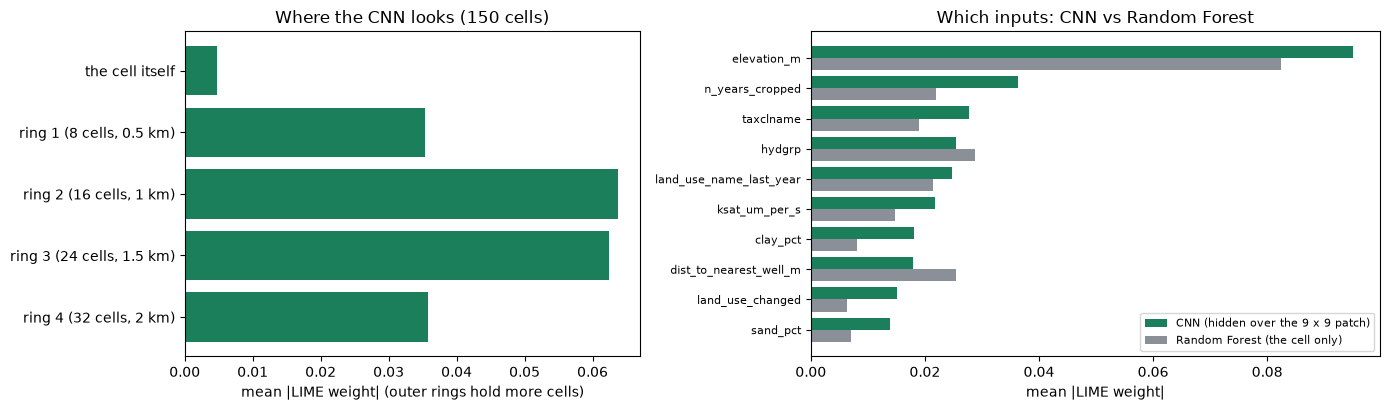

In [24]:
# 7e. What does the CNN rely on? (the same 150 cells)
# (i) where it looks: average |LIME weight| of each ring, and what happens to the predicted class if only the cell itself, or only its surroundings, is hidden
# (ii) which inputs: average |LIME weight| of each input for the CNN and for the Random Forest
ring_abs = np.abs(S["ring_w"]).mean(0)
top_ring = np.bincount(S["ring_w"].argmax(1), minlength=len(RING_NAMES))
only_cell, no_cell = [], []
for i, q in ER.items():
    a = q["base"].copy(); a[RING > 0, :-1] = 0                                  # keep only the cell, hide its 80 neighbours
    b = q["base"].copy(); b[RING == 0, :-1] = 0                                 # hide only the cell itself
    pa, pb = q["classifier_fn"](np.array([a, b]))
    only_cell.append((q["model_p"] - pa[q["label"]], pa.argmax() != q["label"])); no_cell.append((q["model_p"] - pb[q["label"]], pb.argmax() != q["label"]))
only_cell, no_cell = np.array(only_cell, float), np.array(no_cell, float)
S.update(ring_abs=ring_abs, top_ring=top_ring, change_only_cell=float(only_cell[:, 1].mean()), change_no_cell=float(no_cell[:, 1].mean()))
print("(i) where the CNN looks")
print(pd.DataFrame({"mean |LIME weight|": ring_abs, "mean fall in probability when hidden alone": S["occ"].mean(0), "cells where it is LIME's top ring": top_ring}, index=RING_NAMES).round(3).to_string())
print(f"    hide only the cell itself: the predicted class changes in {100 * S['change_no_cell']:.0f}% of the cells (mean fall in probability {no_cell[:, 0].mean():.3f})")
print(f"    keep only the cell, hide its 80 neighbours: the predicted class changes in {100 * S['change_only_cell']:.0f}% of the cells (mean fall {only_cell[:, 0].mean():.3f})")

mI = pd.Series(np.mean([np.abs(EI[i]["weights"]) for i in EI], 0), index=FEATURES); mF = pd.Series(np.mean([np.abs(EF[i]["weights"]) for i in EF], 0), index=FEATURES)
tab = pd.DataFrame({"CNN": mI, "forest": mF}); tab["rank CNN"] = tab["CNN"].rank(ascending=False).astype(int); tab["rank forest"] = tab["forest"].rank(ascending=False).astype(int)
well_inputs = ["gw_decline_m_per_yr_2016_2019", "gw_mean_depth_m", "gw_latest_depth_m", "gw_depth_std_m", "gw_n_measurements", "dist_to_nearest_well_m"]
S.update(rho_models=float(spearmanr(mI, mF)[0]), top5_shared=len(set(mI.nlargest(5).index) & set(mF.nlargest(5).index)),
         same_class=float(np.mean([EI[i]["label"] == EF[i]["label"] for i in EI])), top1_cnn=mI.idxmax(), top1_rf=mF.idxmax(),
         elev_rank_cnn=int(tab.loc["elevation_m", "rank CNN"]), elev_rank_rf=int(tab.loc["elevation_m", "rank forest"]),
         well_share_cnn=float(mI[well_inputs].sum() / mI.sum()), well_share_rf=float(mF[well_inputs].sum() / mF.sum()))
print("\n(ii) which inputs (mean |LIME weight| over the 150 cells, the ten highest for the CNN)")
print(tab.sort_values("rank CNN").head(10).round(3).to_string())
print(f"    rank correlation CNN vs forest over the 23 inputs: {S['rho_models']:.2f} | shared by the two top-5 lists: {S['top5_shared']} | the two models predict the same class for {100 * S['same_class']:.0f}% of these cells")
print(f"    share of the total weight on the well-based inputs (5 source-well columns + distance to the well): CNN {S['well_share_cnn']:.2f} | forest {S['well_share_rf']:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
ax[0].barh(RING_NAMES[::-1], ring_abs[::-1], color=GREEN); ax[0].set_xlabel("mean |LIME weight| (outer rings hold more cells)"); ax[0].set_title("Where the CNN looks (150 cells)")
t10 = tab.sort_values("rank CNN").head(10)[::-1]; yy_ = np.arange(len(t10))
ax[1].barh(yy_ + .2, t10["CNN"], height=.4, color=GREEN, label="CNN (hidden over the 9 x 9 patch)"); ax[1].barh(yy_ - .2, t10["forest"], height=.4, color="#8a8f98", label="Random Forest (the cell only)")
ax[1].set_yticks(yy_); ax[1].set_yticklabels(t10.index, fontsize=8); ax[1].set_xlabel("mean |LIME weight|"); ax[1].legend(fontsize=8); ax[1].set_title("Which inputs: CNN vs Random Forest")
plt.tight_layout(); plt.show()


**Where the CNN looks.** The cell itself carries almost no weight; the rings 1 to 1.5 km away (rings 2 and 3) carry the most in most cells. Hiding only the cell itself changes the predicted class in only a few percent of the cells, while hiding its 80 neighbours (keeping only the cell) changes it in about 70%. So the 9 × 9 CNN predicts mostly from the surroundings of a cell, not from the cell itself.

**This does not mean that the neighbourhood adds information.** The retraining test in the leakage checks found that a network that sees only the cell does about as well (macro-F1 0.361 against 0.349 at the Run 1 budget and 0.356 against 0.380 at the Run 2 budget). A likely reason, which I have not tested, is that the inputs are spatially smooth, so the surroundings largely repeat what the cell itself says and the CNN has learned to read that information from the surroundings. Two cautions: hiding all 80 neighbours gives the CNN an input it never saw, so the 70% overstates how fragile its real predictions are; and the ring weights add up cells (ring 4 holds 32 cells, the cell itself one), so rings are not directly comparable per cell.

**Which inputs.** The CNN and the Random Forest rank the inputs alike (rank correlation about 0.8, elevation first for both, most of the top five the same), yet they predict the same class for fewer than half of these cells: they use much the same inputs but combine them differently, which fits the finding in Step 5 that they fail on many of the same cells but not on all. The well-based inputs (the five source-well columns and the distance to the well) carry about a tenth of the weight in both models. Since the source-well columns hold only four distinct values (Step 2), they act as position tags, not as hydrology.

In [25]:
# 7f. The statements made in the text of this step, checked against THIS run. TensorFlow training is not bit-for-bit repeatable on every machine,
# so a rerun can move the numbers a little; a line that says CHECK means the sentence in the text no longer holds and has to be revised.
chk = [
 ("LIME's local model fits well (median R2 >= 0.7 for the CNN inputs, the CNN rings and the forest inputs)",
  min(S["r2_in"].median(), S["r2_rg"].median(), S["r2_rf"].median()) >= 0.7, f"{S['r2_in'].median():.2f} / {S['r2_rg'].median():.2f} / {S['r2_rf'].median():.2f}"),
 ("hiding LIME's top 3 inputs lowers the probability at least 3 times as much as hiding 3 random inputs, in at least 90% of cells",
  S["d_top"].mean() >= 3 * S["d_rand"].mean() and (S["d_top"] > S["d_rand"]).mean() >= .9, f"{S['d_top'].mean():.3f} vs {S['d_rand'].mean():.3f}, {100 * (S['d_top'] > S['d_rand']).mean():.0f}% of cells"),
 ("LIME's top ring is the ring whose hiding matters most in at least 70% of cells",
  S["hit_rg"] >= .7, f"{100 * S['hit_rg']:.0f}%"),
 ("the top-5 inputs overlap across seeds by at least 0.75 on average (chance 0.13)",
  S["stab_mean"] >= .75, f"{S['stab_mean']:.2f}"),
 ("the cell itself matters little: hiding only the cell changes the class in under 10% of cells, hiding its 80 neighbours in over 50%",
  S["change_no_cell"] < .10 and S["change_only_cell"] > .50, f"{100 * S['change_no_cell']:.0f}% and {100 * S['change_only_cell']:.0f}%"),
 ("rings 2 and 3 (1 to 1.5 km away) are LIME's top ring in at least 60% of the cells",
  S["top_ring"][2:4].sum() / S["top_ring"].sum() >= .6, f"{100 * S['top_ring'][2:4].sum() / S['top_ring'].sum():.0f}%"),
 ("the CNN and the forest rank the inputs alike (rank correlation >= 0.6, at least 3 of their top 5 shared), and elevation is in the top 2 of both",
  S["rho_models"] >= .6 and S["top5_shared"] >= 3 and S["elev_rank_cnn"] <= 2 and S["elev_rank_rf"] <= 2,
  f"{S['rho_models']:.2f}; {S['top5_shared']} of the top 5 shared; elevation ranks {S['elev_rank_cnn']} and {S['elev_rank_rf']}"),
 ("the two models predict the same class for under 60% of the cells",
  S["same_class"] < .6, f"{100 * S['same_class']:.0f}%"),
 ("the well-based inputs carry under 25% of the weight in both models",
  max(S["well_share_cnn"], S["well_share_rf"]) < .25, f"{S['well_share_cnn']:.2f} and {S['well_share_rf']:.2f}"),
]
for text, ok, detail in chk:
    print(("PASS   " if ok else "CHECK  ") + text + "  [" + detail + "]")
print("\n%d of %d statements hold in this run." % (sum(ok for _, ok, _ in chk), len(chk)))


PASS   LIME's local model fits well (median R2 >= 0.7 for the CNN inputs, the CNN rings and the forest inputs)  [0.91 / 0.98 / 0.92]
PASS   hiding LIME's top 3 inputs lowers the probability at least 3 times as much as hiding 3 random inputs, in at least 90% of cells  [0.217 vs 0.029, 100% of cells]
PASS   LIME's top ring is the ring whose hiding matters most in at least 70% of cells  [88%]
PASS   the top-5 inputs overlap across seeds by at least 0.75 on average (chance 0.13)  [0.91]
PASS   the cell itself matters little: hiding only the cell changes the class in under 10% of cells, hiding its 80 neighbours in over 50%  [2% and 70%]
PASS   rings 2 and 3 (1 to 1.5 km away) are LIME's top ring in at least 60% of the cells  [83%]
PASS   the CNN and the forest rank the inputs alike (rank correlation >= 0.6, at least 3 of their top 5 shared), and elevation is in the top 2 of both  [0.83; 4 of the top 5 shared; elevation ranks 1 and 1]
PASS   the two models predict the same class for under 60

**What Step 7 shows, and what it does not.**
- **Shows:** the CNN relies mostly on the cells 1 to 1.5 km around a cell, not on the cell itself, and on a few inputs (elevation first, then years cropped and soil and land-use inputs), much the same inputs as the Random Forest. The explanations fit well, describe what happens when information is removed, and are stable over seeds.
- **Does not show:** that a prediction is right (the CNN is wrong on most of the explained cells (95 of 150 in the saved run, as in Step 4), and a confident wrong prediction is explained as cleanly as a right one); that an input or a place causes subsidence (elevation and the well-based inputs are partly stand-ins for location); or that the neighbourhood adds information (the cell-only network does as well).
- **Limits of this use of LIME:** hiding gives the CNN a blank it never saw; the rings have different sizes; the explanations belong to one trained CNN per fold (seed 42); and the CNN itself is weak (macro-F1 about 0.38), so these explanations describe a weak model.
- **Next test:** the LIME result and the cell-only result would fit together if the surroundings repeat the cell. The cheaper test already in the next steps (neighbourhood averages as extra inputs of the Random Forest) checks this without a CNN.

## Experiment results

In [26]:
def row_(run, configuration, change, key, extra=""):
    s = scores(y, res[key]["pred"])
    return dict(run=run, configuration=configuration, change=change, macro_f1=s["macro_f1"], accuracy=s["accuracy"],
                within_one_class=s["within_one_class"], n_eval=s["n"], fit_s_per_fold=np.mean(res[key]["fit_s"]))

runs = pd.DataFrame([
    row_("ref", "Chance: stratified random guess", "-", "dummy"),
    row_("ref", "Random Forest, 100 trees, scikit-learn defaults (other notebook, Run 1)", "-", "rf"),
    row_("ref", "Random Forest, 100 trees, min_samples_leaf = 5 (other notebook, Run 2)", "-", "rf2"),
    row_("1", f"CNN, {CNN_RUN1['k']}x{CNN_RUN1['k']} patches, {CNN_RUN1['epochs']} epochs, dropout {CNN_RUN1['dropout']}, seed {SEED}", "baseline", "cnn1"),
    row_("2", f"CNN, same, {CNN_RUN2['epochs']} epochs", f"epochs {CNN_RUN1['epochs']} -> {CNN_RUN2['epochs']}", "cnn2"),
]).round(4)
runs.to_csv("experiment_results_cnn.csv", index=False)
print("saved experiment_results_cnn.csv (validation scores; test cells not used)\n")
runs

saved experiment_results_cnn.csv (validation scores; test cells not used)



,run,configuration,change,macro_f1,accuracy,within_one_class,n_eval,fit_s_per_fold
0,ref,Chance: stratified random guess,-,0.2136,0.2138,0.5280,2572,0.0047
1,ref,"Random Forest, 100 trees, scikit-learn default...",-,0.3375,0.3421,0.6081,2572,1.0989
2,ref,"Random Forest, 100 trees, min_samples_leaf = 5...",-,0.3692,0.3799,0.6365,2572,0.3987
3,1,"CNN, 9x9 patches, 30 epochs, dropout 0.3, seed 42",baseline,0.3451,0.3507,0.6392,2572,15.8676
4,2,"CNN, same, 4 epochs",epochs 30 -> 4,0.3784,0.3802,0.6656,2572,3.5048



**Data and evaluation.** `data/subsidence_dataset_processed.csv` (sha256 `ad033f34…`, 5,192 cells, 37 columns). Development data are the 2,572 labeled cells of the 40 training blocks, evaluated with 5-fold cross-validation over whole 5 km blocks (seed 42). The 967 test cells were not scored.

**Initial result.** Macro-F1 0.349 (accuracy 0.354) on 2,572 validation cells, against 0.214 for chance and 0.337 / 0.369 for the Random Forest with defaults / with `min_samples_leaf=5` on the same folds. The 0.50 target in Section 2.1 is not met.

**Failures and limitations.** The CNN overfits after about 4 epochs; labels resting on few InSAR points are predicted worse; confident errors cluster in a few blocks (the same blocks as for the forest) and the confidence is badly overconfident (mean 0.62 against accuracy 0.35); the groundwater inputs hold only four distinct values; and a cell-only network does as well as the 9 × 9 patches, so there is no evidence that the neighbourhood is being used.

**Targeted change.** Training budget 30 → 4 epochs, chosen from the learning curves. Macro-F1 rose from 0.3494 to 0.3801 on the seed-42 folds, but over three seeds the mean gain was only +0.011 ± 0.015 (better on two of three seeds), so the effect on the score is unclear, while training became about five times faster.

**Is the CNN better than the Random Forest here?** No. It is about equal to the forest within the noise, it is slower and needs more care (epochs, seeds), and it adds no clear value from the neighbourhood.

| Run | Configuration | Change | Macro-F1 | Accuracy | Within one class | Cells evaluated | Fit time per fold |
|---|---|---|---|---|---|---|---|
| ref | Chance (stratified guess) | - | 0.2136 | 0.2138 | 0.5280 | 2,572 | < 0.01 s |
| ref | Random Forest, 100 trees, defaults (other notebook) | - | 0.3375 | 0.3421 | 0.6081 | 2,572 | about 0.8 s |
| ref | Random Forest, 100 trees, `min_samples_leaf=5` (other notebook) | - | 0.3692 | 0.3799 | 0.6365 | 2,572 | about 0.3 s |
| 1 | CNN, 9 × 9 patches, 30 epochs, dropout 0.3, seed 42 | baseline | 0.3494 | 0.3538 | 0.6419 | 2,572 | about 18 s |
| 2 | CNN, same, 4 epochs | epochs 30 → 4 | 0.3801 | 0.3826 | 0.6660 | 2,572 | about 4 s |

Same table as `experiment_results_cnn.csv` (validation scores; fit times are from the saved run and depend on the machine).

**Explanation with LIME** I explained the Run 2 CNN on validation cells only, each cell by the CNN of its own fold, with LIME's hide-and-see procedure on two kinds of components: the 23 inputs (hidden over the whole 9 × 9 patch) and five rings of cells around the cell. The CNN relies mostly on the cells 1 to 1.5 km around a cell, not on the cell itself (hiding only the cell changes the predicted class in a few percent of the cells, hiding its 80 neighbours in about 70%), and on elevation first, then years cropped and soil and land-use inputs, much the same inputs as the Random Forest (rank correlation about 0.8). The explanations pass four checks: the local model fits well (median R² about 0.9 for the inputs and 0.98 for the rings); hiding LIME's top three inputs lowers the predicted probability by about 0.22 against 0.03 for random inputs; LIME's top input and top ring match the effect of hiding each alone in about 80 to 90% of the cells; and the top five inputs overlap by about 0.9 across seeds. They do not show that a prediction is right (a confident wrong prediction is explained as cleanly as a right one) or that any input causes subsidence, and since the cell-only network does as well, the surroundings probably repeat what the cell says rather than add information.
